# If You Need a PD, Don't Rebalance

**Companion notebook to the technical note *If You Need a PD, Don't Rebalance: Class Imbalance, Calibration and Decision Thresholds in Credit Scoring*.**

This notebook reproduces, section by section, every number, table and figure of the note, and adds the analysis of variables that the note presents as an appendix. It is meant to be read from top to bottom: each section opens with an explanation of what is done and why, and closes with the conclusions that follow from the output.

## The question

When defaults are rare, a common recommendation is to rebalance the training data: duplicate or synthesise defaults, or give them more weight. The advice comes from classification, where the product is a label (approve or decline). In credit risk the product is usually something else: a **probability of default (PD)** that feeds pricing, provisions and capital. The question of this notebook is what happens to that probability when the data are rebalanced, how much can be repaired afterwards, and where the asymmetry between the two kinds of error should go instead.

## Map

| Notebook section | Section of the note |
|---|---|
| 1. Setup and data | 5.1 Data |
| 2. Analysis of variables | Appendix A |
| 3. Split, preprocessing and models | 5.2 Design |
| 4. Classifying versus estimating | 2 |
| 5. How to evaluate a classifier and a probability | 3 |
| 6. What rebalancing does to the PD | 4 |
| 7. Evidence | 5.3 to 5.5 |
| 8. Where the asymmetry belongs: the threshold | 6 |
| 9. Robustness to the treatment of variables | Appendix A |
| 10. Conclusions | 7 and 8 |

## Requirements

Python 3.10 or later with `numpy`, `pandas`, `scipy`, `scikit-learn`, `statsmodels`, `lightgbm`, `imbalanced-learn` and `matplotlib`. The first code cell checks that they are installed and prints the command to install any that is missing.

The notebook is self-contained: every function is defined in the section where it is first needed, preceded by an explanation of its purpose, its inputs, its logic and its output. Nothing is imported from outside files. A full run takes about five minutes on a modest machine with a single core, and less on a laptop with several.

## 1. Setup and data

### 1.1 Libraries

The first cell checks that every library the notebook needs is installed. Some packages are installed under one name and imported under another: `scikit-learn` is imported as `sklearn` and `imbalanced-learn` as `imblearn`. If anything is missing, the cell stops with the exact command to install it, instead of a long Python error.

In [1]:
import importlib.util
required = {'numpy': 'numpy', 'pandas': 'pandas', 'scipy': 'scipy', 'sklearn': 'scikit-learn',
            'statsmodels': 'statsmodels', 'lightgbm': 'lightgbm', 'imblearn': 'imbalanced-learn',
            'matplotlib': 'matplotlib'}
missing = [pkg for mod, pkg in required.items() if importlib.util.find_spec(mod) is None]
if missing:
    raise SystemExit('Missing packages. Install them with:\n'
                     f'  conda install -c conda-forge {" ".join(missing)}\n'
                     f'or, from this notebook:\n  %pip install {" ".join(missing)}\n'
                     'Then restart the kernel.')
print('All required packages are installed.')

All required packages are installed.


In [2]:
import os
os.environ.setdefault('OMP_NUM_THREADS', '2')   # keeps the run light on laptops
import hashlib, io, time, urllib.request, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import statsmodels.api as sm
from scipy.optimize import brentq, minimize
from scipy.special import expit, logit
from scipy.stats import beta as beta_dist, chi2
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, log_loss,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

### 1.2 Configuration

All the random choices of the notebook (data splits, undersampling, SMOTE, the subsampling inside LightGBM) depend on one seed, so that every run gives the same numbers.

`LGB_PARAMS` fixes the settings of LightGBM for every model in the notebook. The budget is fixed at 250 trees, with no early stopping, so that differences between variants come only from the treatment of the data:

- `learning_rate=0.03` and `num_leaves=31`: small steps and moderately sized trees;
- `min_child_samples=200`: no leaf with fewer than about 200 borrowers, a strong guard against overfitting;
- `subsample=0.8`, `subsample_freq=1`, `colsample_bytree=0.8`: each tree sees a random 80% of the borrowers and of the variables;
- `reg_lambda=1.0`: a light L2 penalty on the leaf values;
- `objective='binary'`: the loss is the log-loss, so the model aims at a probability.

In [3]:
SEED = 2026
N_JOBS = 2
LGB_PARAMS = dict(n_estimators=250, learning_rate=.03, num_leaves=31, min_child_samples=200,
                  subsample=.8, subsample_freq=1, colsample_bytree=.8, reg_lambda=1.0,
                  objective='binary', metric='binary_logloss', random_state=SEED,
                  verbosity=-1, n_jobs=N_JOBS)

### 1.3 The data

*Give Me Some Credit* was a Kaggle competition held between September and December 2011 (https://www.kaggle.com/c/GiveMeSomeCredit; downloading it from Kaggle requires a free account). The labelled training file has 150,000 borrowers. The event, `SeriousDlqin2yrs`, flags serious delinquency (90 days past due or worse) within the following two years. There are ten characteristics: utilisation of revolving lines, age, three delinquency counters (30 to 59, 60 to 89 and 90 or more days), debt ratio, monthly income, open credit lines, real estate loans and number of dependents.

**Function `load_gmsc(local_path, url)`**

- *Purpose:* read the data with verifiable provenance.
- *Inputs:* the path of a local copy of `cs-training.csv` and the URL of an identical public copy on GitHub.
- *Logic:* if the local file exists it is read; otherwise the public copy is downloaded. The SHA-256 hash of the bytes is compared with the hash of the verified copy, and a warning is issued if they differ, because then the numbers of this notebook may not be reproduced. The columns are renamed to short names (`util`, `age`, `dpd30`, `dpd60`, `dpd90`, `debt_ratio`, `income`, `open_lines`, `real_estate`, `dependents`), and the function checks that every borrower appears once and that the label is binary with no missing values.
- *Output:* the DataFrame, the source used and the hash.

In [4]:
GMSC_URL = ('https://raw.githubusercontent.com/DrIanGregory/Kaggle-GiveMeSomeCredit/'
            'master/data/GiveMeSomeCredit-training.csv')
GMSC_SHA256 = 'e333eb8001576d7eb140cdfad9801c6b000ddfa6a528b6268a640230eb2a9994'
RENAME = {'SeriousDlqin2yrs': 'y', 'RevolvingUtilizationOfUnsecuredLines': 'util', 'age': 'age',
          'NumberOfTime30-59DaysPastDueNotWorse': 'dpd30', 'DebtRatio': 'debt_ratio',
          'MonthlyIncome': 'income', 'NumberOfOpenCreditLinesAndLoans': 'open_lines',
          'NumberOfTimes90DaysLate': 'dpd90', 'NumberRealEstateLoansOrLines': 'real_estate',
          'NumberOfTime60-89DaysPastDueNotWorse': 'dpd60', 'NumberOfDependents': 'dependents'}

def load_gmsc(local_path='cs-training.csv', url=GMSC_URL):
    path = Path(local_path)
    if path.is_file():
        content, source = path.read_bytes(), f'local file {path.name}'
    else:
        with urllib.request.urlopen(url, timeout=60) as response:
            content = response.read()
        source = url
    sha = hashlib.sha256(content).hexdigest()
    if sha != GMSC_SHA256:
        warnings.warn('The file differs from the verified copy: check its provenance and the results.')
    df = pd.read_csv(io.BytesIO(content), index_col=0).rename(columns=RENAME)
    assert df.index.is_unique and not df.y.isna().any() and set(df.y.unique()) == {0, 1}
    df['y'] = df.y.astype(int)
    return df, source, sha

df, source, sha = load_gmsc()
y_all = df.y.to_numpy()
print('Source:', source)
print('SHA-256 matches the verified copy:', sha == GMSC_SHA256)
print(f'Borrowers: {len(df):,} | defaults: {int(df.y.sum()):,} | default rate: {df.y.mean():.2%}')
display(df.describe(percentiles=[.01, .5, .99]).T)

Source: https://raw.githubusercontent.com/DrIanGregory/Kaggle-GiveMeSomeCredit/master/data/GiveMeSomeCredit-training.csv
SHA-256 matches the verified copy: True
Borrowers: 150,000 | defaults: 10,026 | default rate: 6.68%


,count,mean,std,min,1%,50%,99%,max
y,"150,000.0000",0.0668,0.2497,0.0000,0.0000,0.0000,1.0000,1.0000
util,"150,000.0000",6.0484,249.7554,0.0000,0.0000,0.1542,1.0930,"50,708.0000"
age,"150,000.0000",52.2952,14.7719,0.0000,24.0000,52.0000,87.0000,109.0000
dpd30,"150,000.0000",0.4210,4.1928,0.0000,0.0000,0.0000,4.0000,98.0000
debt_ratio,"150,000.0000",353.0051,"2,037.8185",0.0000,0.0000,0.3665,"4,979.0400","329,664.0000"
income,"120,269.0000","6,670.2212","14,384.6742",0.0000,0.0000,"5,400.0000","25,000.0000","3,008,750.0000"
open_lines,"150,000.0000",8.4528,5.1460,0.0000,0.0000,8.0000,24.0000,58.0000
dpd90,"150,000.0000",0.2660,4.1693,0.0000,0.0000,0.0000,3.0000,98.0000
real_estate,"150,000.0000",1.0182,1.1298,0.0000,0.0000,1.0000,4.0000,54.0000
dpd60,"150,000.0000",0.2404,4.1552,0.0000,0.0000,0.0000,2.0000,98.0000


### Conclusion of the section

The file has 150,000 borrowers and 10,026 defaults: a default rate of 6.68%. The descriptive table already shows several problems: the maximum of the delinquency counters is 98, although nobody can be late 98 times in two years; utilisation reaches values in the tens of thousands; the debt ratio has an enormous tail; and income and number of dependents have missing values. These fields need to be understood before any model is fitted.

## 2. Analysis of variables

### Why start here

A model does not know what a number means. If a field mixes counts with codes, ratios with amounts, or zeros that mean "not applicable" with real zeros, the model will learn false relationships, and no rebalancing or calibration technique will fix that later. This section reviews four cases and then summarises the predictive power of each variable on its own.

### Tools

- **Default rate by group**: the most direct way to see whether a group behaves differently.
- **WoE and IV.** For a variable cut into bins, the *weight of evidence* of a bin is $\ln(\%\text{goods}/\%\text{bads})$: positive where good borrowers are over-represented. The *information value* is $\sum(\%\text{goods}-\%\text{bads})\cdot\text{WoE}$ and summarises how well the variable separates the two classes. The usual scorecard convention reads: below 0.02 not predictive, 0.02 to 0.1 weak, 0.1 to 0.3 medium, above 0.3 strong.
- **Raw Gini versus WoE Gini.** The raw Gini uses the variable as it is as a score, so it only captures monotone relationships. The WoE Gini uses the WoE of each bin as the score, so it also captures U-shaped relationships and special groups.

### Functions

- `woe_table(lab, y)`: takes the bin label of each borrower and its outcome. It counts goods and bads by bin, adds 0.5 to each count to avoid logarithms of zero, and computes WoE, IV and the Gini of using the WoE as a score. It returns the IV, the Gini and the table by bin with its default rate.
- `bins(x, q, special)`: cuts the regular values into `q` quantiles by rank (so that ties do not collapse bins) and puts in their own group the borrowers that carry a label in `special`, for example "no income".

In [5]:
def woe_table(lab, y):
    t = pd.DataFrame({'b': lab, 'y': y}).groupby('b').y.agg(['sum', 'count'])
    bads, goods = t['sum'] + .5, t['count'] - t['sum'] + .5
    pb, pg = bads / bads.sum(), goods / goods.sum()
    woe = np.log(pg / pb)
    iv = ((pg - pb) * woe).sum()
    gini = 2 * roc_auc_score(y, -lab.map(woe)) - 1
    return iv, gini, t.rename(columns={'sum': 'bads', 'count': 'N'}).assign(rate=t['sum'] / t['count'], WoE=woe)

def bins(x, q=10, special=None):
    lab = pd.Series(index=x.index, dtype=object)
    sp = special.notna() if special is not None else pd.Series(False, index=x.index)
    lab[~sp] = 'q' + pd.qcut(x[~sp].rank(method='first'), q, labels=False).astype(int).astype(str)
    if sp.any():
        lab[sp] = special[sp]
    return lab

group = lambda cond, name: pd.Series(np.where(cond, name, None), index=df.index)

### 2.1 The codes 96 and 98 in the delinquency counters

The competition describes the three delinquency fields as counts of past-due events in the previous two years. The next cell checks the maximum reached by genuine counts, how many borrowers carry 96 or 98, whether they carry them in all three fields at once, and what their profile looks like.

In credit bureau reporting, codes in the nineties are typically reserved for states that are not counts at all: accounts written off, very advanced delinquency or fraud. The competition does not document what 96 and 98 mean in this file, so that reading is an interpretation; what can be checked is whether the profile of the group is consistent with it.

In [6]:
dlq = df[['dpd30', 'dpd60', 'dpd90']]
code9x = dlq.isin([96, 98]).any(axis=1)
print('Maximum of each counter without codes:', dlq[~code9x].max().to_dict())
print(f'Borrowers with 96 or 98: {int(code9x.sum())} | in all three fields at once: {dlq[code9x].isin([96, 98]).all(axis=1).mean():.0%}')
print(f'Default rate with a code: {df.y[code9x].mean():.1%} | without: {df.y[~code9x].mean():.1%}')
display(df.loc[code9x, ['util', 'debt_ratio', 'open_lines', 'income']].median().to_frame('median, coded borrowers'))

Maximum of each counter without codes: {'dpd30': 13, 'dpd60': 11, 'dpd90': 17}
Borrowers with 96 or 98: 269 | in all three fields at once: 100%
Default rate with a code: 54.6% | without: 6.6%


,"median, coded borrowers"
util,1.0000
debt_ratio,0.0000
open_lines,0.0000
income,"2,168.5000"


**Conclusion.** Genuine counts never exceed 17, while 269 borrowers carry 96 or 98, and they carry them in all three fields at once: these values are not counts. Their profile is that of accounts closed after severe deterioration (median utilisation of 100%, no open lines, debt ratio of zero), and their default rate is 54.6%, eight times that of the portfolio. Imputing them as missing would erase the strongest risk signal in the data, replacing them by zero would turn the riskiest borrowers into borrowers with a clean history, and keeping them as counts would tell a linear model that 98 late payments is a meaningful number. The preprocessing used in this notebook (section 3) creates an indicator, `f_code9x`, and sets the counters to zero only as a neutral placeholder, so that the indicator carries all the information. With 269 borrowers the segment is also a calibration hazard: a model can get it badly wrong while looking fine on average.

### 2.2 Missing income and zero income

A missing income can mean different things: the channel or product did not ask for it (pre-approved offers to existing customers, for instance), the capture process failed, or the applicant refused to disclose it. Each mechanism carries a different risk. If the absence depends only on something recorded, such as the channel, it is "missing at random" in the statistical sense; if it depends on the undisclosed income itself, it is not. The cell compares default rates, checks whether missing dependents coincide with missing income, and looks at what the debt ratio contains when income is missing.

In [7]:
no_income, no_dep, zero_income = df.income.isna(), df.dependents.isna(), df.income == 0
print(f'Missing income: {no_income.mean():.1%} | default rate {df.y[no_income].mean():.1%} against {df.y[~no_income].mean():.1%} with income')
print(f'Missing dependents: {int(no_dep.sum()):,} | of them without income: {no_income[no_dep].mean():.0%}')
print(f'Median debt ratio without income: {df.debt_ratio[no_income].median():,.0f} | with income: {df.debt_ratio[~no_income].median():.2f}')
print(f'Income reported as zero: {int(zero_income.sum()):,} borrowers | default rate {df.y[zero_income].mean():.1%}')

Missing income: 19.8% | default rate 5.6% against 6.9% with income
Missing dependents: 3,924 | of them without income: 100%
Median debt ratio without income: 1,159 | with income: 0.30
Income reported as zero: 1,634 borrowers | default rate 4.0%


**Conclusion.** Income is missing for 19.8% of the borrowers, and that group defaults less often (5.6% against 6.9%). This is more consistent with a channel or process effect than with concealment, although the default rate alone cannot identify the mechanism. Two further signs point the same way: every borrower with missing dependents also has missing income (a common origin), and their debt ratio has a median of 1,159 against 0.30, so for them the field looks like an amount rather than a ratio. An income reported as zero (1,634 borrowers, 4.0%) is a separate case. The operational conclusion does not depend on the mechanism: the absence carries information, so it is represented by indicators (`f_no_income`, `f_no_dependents`) created **before** imputing, and in practice it pays to find out where the missing values come from and to monitor their share by channel.

### 2.3 Revolving utilisation

This is the strongest variable in the file. The cell computes the default rate by bin, keeping apart the value of exactly zero and the values of 100 or more (10,000%).

In [8]:
u = df.util
util_bins = [('0', u == 0), ('(0, 0.01]', (u > 0) & (u <= .01)), ('(0.01, 0.1]', (u > .01) & (u <= .1)),
             ('(0.1, 0.3]', (u > .1) & (u <= .3)), ('(0.3, 0.5]', (u > .3) & (u <= .5)), ('(0.5, 0.7]', (u > .5) & (u <= .7)),
             ('(0.7, 0.9]', (u > .7) & (u <= .9)), ('(0.9, 1]', (u > .9) & (u <= 1)), ('(1, 100)', (u > 1) & (u < 100)),
             ('100+', u >= 100)]
t_u = pd.DataFrame([(l, int(m.sum()), df.y[m].mean()) for l, m in util_bins], columns=['bin', 'N', 'rate']).set_index('bin')
display(t_u)
print(f'99th percentile of utilisation: {u.quantile(.99):.2f}')

,N,rate
bin,,
0,10878,0.0294
"(0, 0.01]",11445,0.0128
"(0.01, 0.1]",42081,0.0166
"(0.1, 0.3]",28478,0.0314
"(0.3, 0.5]",15830,0.0585
"(0.5, 0.7]",11340,0.0957
"(0.7, 0.9]",9879,0.1486
"(0.9, 1]",16748,0.1940
"(1, 100)",3098,0.3957


99th percentile of utilisation: 1.09


**Conclusion.** Two groups break the trend. The 10,878 borrowers with a utilisation of exactly zero default more often (2.9%) than those with a small positive balance (1.3%). The data do not say why: a zero can mean that the borrower has no revolving lines at all, or that the lines exist but carry no balance. Either way, the group does not behave like the bottom of a continuous scale. At the other end, the risk rises steadily up to 100% and reaches about 40% above it, and then collapses: the 223 borrowers with a value of 100 or more default only 4.9% of the time. Those values are almost certainly not ratios. Capping at the 99th percentile (1.09), as the simple preprocessing does, sends that group to the riskiest bucket. Section 9 measures the effect of treating both groups separately.

### 2.4 Debt ratio

The debt ratio has a very long tail and, as section 2.2 showed, mixes ratios with amounts. The cell shows the default rate by decile among borrowers with income, with the no-income group kept apart, and plots both variables.

,N,rate
bin,,
D1,12027,0.0493
D2,12027,0.0693
D3,12027,0.0629
D4,12027,0.0591
D5,12027,0.0530
D6,12026,0.0546
D7,12027,0.0672
D8,12027,0.0747
D9,12027,0.0968


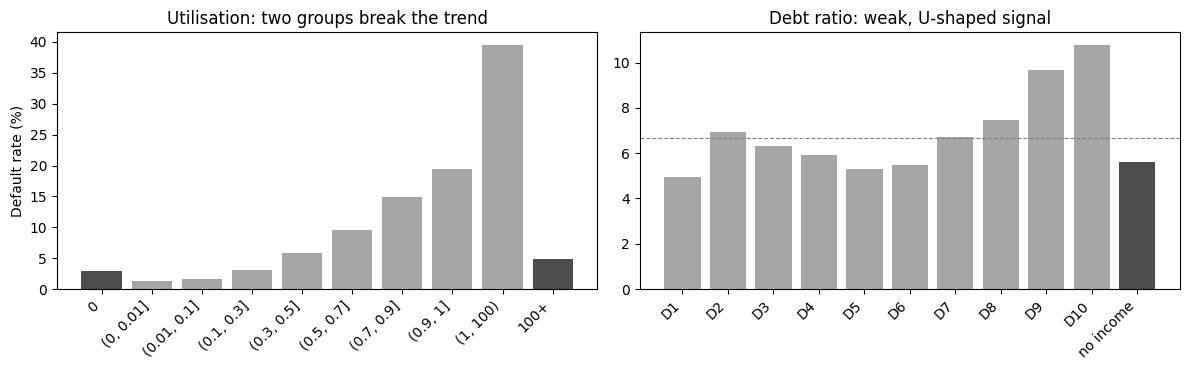

In [9]:
dec = pd.qcut(df.debt_ratio[~no_income].rank(method='first'), 10, labels=False)
t_d = pd.DataFrame([(f'D{k + 1}', int((dec == k).sum()), df.y[~no_income][dec == k].mean()) for k in range(10)]
                   + [('no income', int(no_income.sum()), df.y[no_income].mean())], columns=['bin', 'N', 'rate']).set_index('bin')
display(t_d)

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
axs[0].bar(range(len(t_u)), 100 * t_u.rate, color=['0.3' if l in ('0', '100+') else '0.65' for l in t_u.index])
axs[0].set_xticks(range(len(t_u))); axs[0].set_xticklabels(t_u.index, rotation=45, ha='right')
axs[0].set(ylabel='Default rate (%)', title='Utilisation: two groups break the trend')
axs[1].bar(range(len(t_d)), 100 * t_d.rate, color=['0.65'] * 10 + ['0.3'])
axs[1].set_xticks(range(len(t_d))); axs[1].set_xticklabels(t_d.index, rotation=45, ha='right')
axs[1].axhline(100 * df.y.mean(), color='0.5', ls='--', lw=.8)
axs[1].set(title='Debt ratio: weak, U-shaped signal')
plt.tight_layout(); plt.show()

**Conclusion.** The relationship is U-shaped: 4.9% in the lowest decile, a minimum around a ratio of 0.25 to 0.30, and 10.8% in the highest decile. A variable like this looks useless when it enters a linear model raw, but it can contribute once the no-income group is kept apart and its shape is respected.

### 2.5 Choosing the cuts: from fine to coarse classing

Deciles are a convenient default, but they are not chosen with the outcome in mind. The scorecard tradition splits the task in two steps:

- **Fine classing**: cut the variable into many small bins, here up to 50 quantiles of the regular values. Special groups (codes 9x, missing income, zero utilisation, 100+) are kept apart from the start and never merged with regular values, because their meaning is different.
- **Coarse classing**: merge adjacent bins whose default rates are not distinguishable, until every remaining bin is large enough and different from its neighbours.

The merging rule used here is the classic **ChiMerge** idea (Kerber, 1992): for each pair of adjacent bins, a chi-square test asks whether their default rates could be the same. The pair that looks most alike is merged first, and the process stops when every adjacent pair differs at a chosen significance level. A minimum bin size is also imposed, because a WoE estimated on a handful of borrowers is noise. Here it is 2% of the borrowers, about 2,100 in the development sample. A floor of 5%, also common in practice, would be too coarse for this file: only 4.9% of the borrowers have ever been 60 to 89 days late, and a 5% floor would merge them with everybody else and erase the strongest signal of that variable. No monotonicity is imposed, so U-shaped relationships such as the debt ratio can survive.

**Function `chi2_adjacent(bads, ns)`**

- *Purpose:* measure how different the default rates of each pair of adjacent bins are.
- *Inputs:* arrays with the number of defaults and of borrowers in each bin, in order.
- *Logic:* for each adjacent pair builds the 2x2 table (defaults and non-defaults in each bin) and computes the Pearson chi-square statistic, $n(ad-bc)^2/[(a+b)(c+d)(a+c)(b+d)]$. A small value means the two bins have similar default rates.
- *Output:* array of statistics, one per adjacent pair.

**Function `chimerge(x, y, max_fine=50, min_share=0.02, alpha=0.05)`**

- *Purpose:* find the cut points of a variable.
- *Inputs:* the regular values `x` (special groups already removed), their outcomes `y`, the number of fine bins, the minimum share of borrowers per final bin and the significance level.
- *Logic:* starts from the distinct quantiles of `x` as fine cuts. Then, repeatedly: if some bin holds less than `min_share` of the borrowers, it is merged with the neighbour whose default rate is closer (smaller chi-square); otherwise, if the most similar adjacent pair is not significantly different (p-value above `alpha`), that pair is merged; otherwise the process stops.
- *Output:* the list of interior cut points.

**Function `binned_labels(x, cuts, special)`**: assigns each borrower to the bin $(c_{k-1}, c_k]$ given by the cut points, labelled with its interval, or to its special group.

**The experiment.** Cut points chosen with the outcome can overfit: they are tuned to the noise of the sample. To see it, the data are split once into a 70% development part and a 30% holdout part. For each variable, deciles and ChiMerge bins are both built on the development part, and the IV and WoE Gini are measured on both parts.

In [10]:
def chi2_adjacent(bads, ns):
    a, b = bads[:-1], ns[:-1] - bads[:-1]
    c, d = bads[1:], ns[1:] - bads[1:]
    n = a + b + c + d
    den = (a + b) * (c + d) * (a + c) * (b + d)
    return np.where(den > 0, n * (a * d - b * c) ** 2 / np.where(den > 0, den, 1), 0.0)

def chimerge(x, y, max_fine=50, min_share=0.02, alpha=0.05):
    x, y = np.asarray(x, float), np.asarray(y)
    cuts = list(np.unique(np.quantile(x, np.linspace(0, 1, max_fine + 1)[1:-1])))
    while cuts:
        idx = np.searchsorted(cuts, x, side='left')           # bin of each borrower: (-inf, c1], (c1, c2], ...
        ns = np.bincount(idx, minlength=len(cuts) + 1).astype(float)
        bads = np.bincount(idx, weights=y, minlength=len(cuts) + 1)
        if (ns == 0).any():                                   # an empty bin: drop one of its borders
            k = int(np.flatnonzero(ns == 0)[0])
            del cuts[min(k, len(cuts) - 1)]
            continue
        stats = chi2_adjacent(bads, ns)
        small = np.flatnonzero(ns / len(x) < min_share)
        if len(small):
            k = small[np.argmin(ns[small])]                   # smallest bin
            if k == 0:
                pair = 0
            elif k == len(ns) - 1:
                pair = k - 1
            else:
                pair = k - 1 if stats[k - 1] <= stats[k] else k
        elif chi2.sf(stats.min(), 1) > alpha:
            pair = int(np.argmin(stats))                      # most similar pair
        else:
            break
        del cuts[pair]                                        # merging two bins removes the cut between them
    return cuts

def binned_labels(x, cuts, special=None):
    edges = [-np.inf] + list(cuts) + [np.inf]
    names = [f'{k:02d}: ({edges[k]:.3g}, {edges[k + 1]:.3g}]' for k in range(len(edges) - 1)]
    lab = pd.Series(np.array(names, dtype=object)[np.searchsorted(cuts, x.to_numpy(float), side='left')], index=x.index)
    if special is not None:
        sp = special.notna()
        lab[sp] = special[sp]
    return lab

dev_idx, hold_idx = train_test_split(df.index, test_size=.30, stratify=df.y, random_state=SEED)
dev, hold = df.loc[dev_idx], df.loc[hold_idx]

def specials(d):
    # special groups of each variable, kept apart from the regular values
    c9 = d[['dpd30', 'dpd60', 'dpd90']].isin([96, 98]).any(axis=1)
    sp = lambda cond, name: pd.Series(np.where(cond, name, None), index=d.index)
    return {'util': sp(d.util == 0, 'zero').where(d.util < 100, '100+'),
            'debt_ratio': sp(d.income.isna(), 'no income'),
            'income': sp(d.income.isna(), 'missing').where(~(d.income == 0), 'zero'),
            'age': sp(d.age < 18, 'invalid'), 'open_lines': sp(False, None), 'real_estate': sp(False, None),
            'dependents': sp(d.dependents.isna(), 'missing'),
            'dpd30': sp(c9, 'code 9x'), 'dpd60': sp(c9, 'code 9x'), 'dpd90': sp(c9, 'code 9x')}

sp_dev, sp_hold = specials(dev), specials(hold)
rows, CUTS = [], {}
for v in ['util', 'dpd90', 'dpd30', 'dpd60', 'age', 'income', 'open_lines', 'debt_ratio', 'real_estate', 'dependents']:
    reg_dev = sp_dev[v].isna()
    # deciles on the development part (regular values only), applied to both parts
    dec_cuts = list(np.unique(np.quantile(dev[v][reg_dev], np.linspace(0, 1, 11)[1:-1])))
    cm_cuts = chimerge(dev[v][reg_dev], dev.y[reg_dev])
    CUTS[v] = cm_cuts
    out = {'variable': v}
    for name, cuts in [('deciles', dec_cuts), ('ChiMerge', cm_cuts)]:
        for part, d, spd in [('dev', dev, sp_dev), ('holdout', hold, sp_hold)]:
            lab = binned_labels(d[v].fillna(-1), cuts, spd[v])
            iv, g, _ = woe_table(lab, d.y.to_numpy())
            out[f'IV {name} {part}'] = iv
        out[f'bins {name}'] = len(cuts) + 1
    rows.append(out)
cmp = pd.DataFrame(rows).set_index('variable')
display(cmp[['bins deciles', 'IV deciles dev', 'IV deciles holdout', 'bins ChiMerge', 'IV ChiMerge dev', 'IV ChiMerge holdout']].round(3))

,bins deciles,IV deciles dev,IV deciles holdout,bins ChiMerge,IV ChiMerge dev,IV ChiMerge holdout
variable,,,,,,
util,10,1.1350,1.1150,13,1.1890,1.1700
dpd90,2,0.8400,0.8390,2,0.8400,0.8390
dpd30,3,0.7270,0.7930,4,0.7390,0.8040
dpd60,2,0.5700,0.5930,2,0.5700,0.5930
age,10,0.2730,0.2300,10,0.2810,0.2300
income,10,0.0820,0.0790,11,0.0930,0.0820
open_lines,10,0.0680,0.0660,10,0.1030,0.0950
debt_ratio,10,0.0660,0.0720,14,0.1020,0.0960
real_estate,4,0.0570,0.0510,4,0.0660,0.0530


**Reading the table.** The number of bins counts only the regular values; special groups come on top. The comparison that matters is on the holdout part, which played no role in choosing the cuts. For utilisation, open lines and the debt ratio, ChiMerge reaches a clearly higher holdout IV than deciles (1.170 against 1.115, 0.095 against 0.066 and 0.096 against 0.072), and the gap between development and holdout stays small: the gain is not just fitted noise. For age and the delinquency counters the two methods are almost equivalent, because the counters have few distinct values and age has a smooth relationship. The cut points of the debt ratio and of utilisation are shown next.

In [11]:
for v in ['debt_ratio', 'util']:
    lab = binned_labels(df[v].fillna(-1), CUTS[v], specials(df)[v])
    _, _, t = woe_table(lab, y_all)
    print(f'{v}: cut points {np.round(CUTS[v], 3).tolist()}')
    order = sorted(t.index, key=lambda b: (': (' not in b, b))   # regular bins first, special groups last
    display(t.loc[order, ['N', 'bads', 'rate', 'WoE']].round(4))

debt_ratio: cut points [0.0, 0.012, 0.022, 0.058, 0.225, 0.32, 0.419, 0.454, 0.473, 0.517, 0.65, 1.007, 4.533]


,N,bads,rate,WoE
b,,,,
"00: (-inf, 0]",2491,231,0.0927,-0.3568
"01: (0, 0.012]",7113,236,0.0332,0.7345
"02: (0.012, 0.0224]",2479,133,0.0537,0.2310
"03: (0.0224, 0.0583]",4765,349,0.0732,-0.0990
"04: (0.0583, 0.225]",28746,1806,0.0628,0.0667
"05: (0.225, 0.32]",19274,1012,0.0525,0.2568
"06: (0.32, 0.419]",16939,1042,0.0615,0.0890
"07: (0.419, 0.454]",4776,361,0.0756,-0.1330
"08: (0.454, 0.473]",2429,160,0.0659,0.0134


util: cut points [0.06, 0.137, 0.211, 0.315, 0.415, 0.493, 0.684, 0.741, 0.855, 0.954, 0.994, 1.006]


,N,bads,rate,WoE
b,,,,
"00: (-inf, 0.0605]",41638,598,0.0144,1.5923
"01: (0.0605, 0.137]",19495,421,0.0216,1.1767
"02: (0.137, 0.211]",11114,352,0.0317,0.7832
"03: (0.211, 0.315]",11201,444,0.0396,0.5508
"04: (0.315, 0.415]",8359,455,0.0544,0.2182
"05: (0.415, 0.493]",5538,360,0.0650,0.0292
"06: (0.493, 0.684]",11030,1034,0.0937,-0.3673
"07: (0.684, 0.741]",2790,337,0.1208,-0.6519
"08: (0.741, 0.855]",5533,808,0.1460,-0.8700


**Figure.** The figure of the companion note: on the left, the default rate by utilisation group of section 2.3, with zero and 100+ in dark; on the right, the default rate of the debt ratio in the bins chosen by ChiMerge on the development part (borrowers with income, all data), with the two special ends (a ratio of zero and the top bin) and the no-income group in dark.

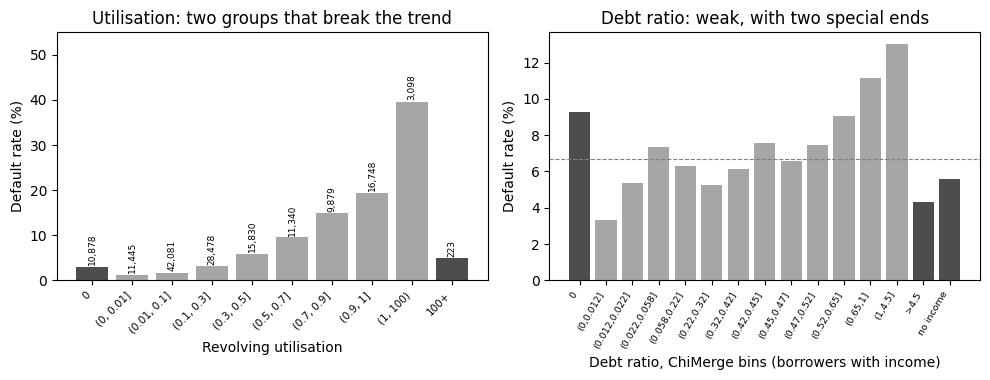

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.9))
axs[0].bar(range(len(t_u)), 100 * t_u.rate, color=['0.3' if l in ('0', '100+') else '0.65' for l in t_u.index])
axs[0].set_xticks(range(len(t_u))); axs[0].set_xticklabels(t_u.index, rotation=45, ha='right', fontsize=7.5)
for i, (r_, n_) in enumerate(zip(100 * t_u.rate, t_u.N)):
    axs[0].text(i, r_ + .8, f'{n_:,}', ha='center', fontsize=6.5, rotation=90)
axs[0].set(ylabel='Default rate (%)', xlabel='Revolving utilisation', ylim=(0, 55), title='Utilisation: two groups that break the trend')
cuts = CUTS['debt_ratio']; edges = [-np.inf] + list(cuts) + [np.inf]
k = np.searchsorted(cuts, df.debt_ratio.to_numpy(float), side='left'); inc = ~no_income.to_numpy()
labels, rates = [], []
for b in range(len(edges) - 1):
    lo, hi = edges[b], edges[b + 1]
    labels.append('0' if (b == 0 and hi == 0) else (f'>{lo:.2g}' if hi == np.inf else f'({lo:.2g},{hi:.2g}]'))
    rates.append(100 * df.y[(k == b) & inc].mean())
labels.append('no income'); rates.append(100 * df.y[no_income].mean())
colors = ['0.65'] * len(labels); colors[0] = colors[-2] = colors[-1] = '0.3'
axs[1].bar(range(len(labels)), rates, color=colors)
axs[1].set_xticks(range(len(labels))); axs[1].set_xticklabels(labels, rotation=60, ha='right', fontsize=6.8)
axs[1].axhline(100 * df.y.mean(), color='0.5', lw=.8, ls='--')
axs[1].set(ylabel='Default rate (%)', xlabel='Debt ratio, ChiMerge bins (borrowers with income)', title='Debt ratio: weak, with two special ends')
plt.tight_layout(); plt.show()

**Conclusion.** Choosing the cuts with the outcome reveals groups that deciles hide:

- **Debt ratio.** A ratio of exactly zero (2,491 borrowers) defaults 9.3% of the time, far more than a small positive ratio (3.3%): the same pattern as zero utilisation. In the middle, the U shape of section 2.4 reappears. And above a ratio of about 4.5 the risk drops again (4.3%), like the no-income group: those values probably are amounts rather than ratios, which reinforces the reading of section 2.2.
- **Utilisation.** The bins separate the borrowers at their limit (utilisation between 0.994 and 1.006, 19.2%) from those above it (40.7%): being over the limit is a much stronger signal than being at it.

ChiMerge has its own settings (number of fine bins, minimum share, significance level), and different settings give different cuts; they are choices to be justified, like any other. In addition, the IV measured on the same data used to choose the cuts is optimistic, so the cuts are chosen on a development sample and judged on a separate one, as done here. In a real scorecard the bins are also reviewed for business sense, and some policies require monotone WoE patterns; ChiMerge does not impose them.

### 2.6 Predictive power of each variable on its own

The table summarises each variable with two binnings, both built on the development part: deciles and ChiMerge. **Every number is measured on the holdout part**, so that none of them benefits from the choice of cuts:

- **|Gini| raw:** the variable used as it is as a score (missing values filled with the median). It only captures monotone relationships, and it mixes special groups with regular values.
- **Gini WoE:** the score is the WoE of the bin of each borrower, so U shapes and special groups count. The WoE values are **learned on the development part and applied, frozen, to the holdout part**, exactly as a scorecard would use them on new borrowers.
- **IV:** the information value of the bins chosen on the development part, computed with the counts of the holdout part. It measures how well the partition separates goods from bads in new data.

**Function `frozen_woe_gini(lab_dev, y_dev, lab_hold, y_hold)`**: learns the WoE of each bin with `woe_table` on the development part, maps each holdout borrower to the WoE of its bin (a bin that does not appear in development gets a neutral WoE of zero), and returns the Gini of that score on the holdout part.

At the end, the whole procedure for the debt ratio (development and holdout split, choice of cuts, holdout IV) is repeated on ten different random splits, for both binnings, to see how stable its IV is.

In [13]:
def frozen_woe_gini(lab_dev, y_dev, lab_hold, y_hold):
    _, _, t = woe_table(lab_dev, y_dev)
    score = -lab_hold.map(t['WoE']).astype(float).fillna(0.0)
    return 2 * roc_auc_score(y_hold, score) - 1

rows = []
for v in ['util', 'dpd90', 'dpd30', 'dpd60', 'age', 'income', 'open_lines', 'debt_ratio', 'real_estate', 'dependents']:
    reg_dev = sp_dev[v].isna()
    dec_cuts = list(np.unique(np.quantile(dev[v][reg_dev], np.linspace(0, 1, 11)[1:-1])))
    x = hold[v].where(sp_hold[v].isna() | (v not in ('dpd30', 'dpd60', 'dpd90')), 0)   # coded counters as 0 for the raw score
    row = {'variable': v, '|Gini| raw': abs(2 * roc_auc_score(hold.y, x.fillna(x.median())) - 1)}
    for name, cuts in [('deciles', dec_cuts), ('ChiMerge', CUTS[v])]:
        lab_d = binned_labels(dev[v].fillna(-1), cuts, sp_dev[v])
        lab_h = binned_labels(hold[v].fillna(-1), cuts, sp_hold[v])
        iv = woe_table(lab_h, hold.y.to_numpy())[0]
        g = frozen_woe_gini(lab_d, dev.y.to_numpy(), lab_h, hold.y.to_numpy())
        row.update({f'bins {name}': len(cuts) + 1, f'Gini WoE {name}': g, f'IV {name}': iv})
    rows.append(row)
display(pd.DataFrame(rows).set_index('variable').round(3))

ivs = {'deciles': [], 'ChiMerge': []}
for k in range(10):
    i_dev, i_hold = train_test_split(df.index, test_size=.30, stratify=df.y, random_state=SEED + 100 + k)
    dv, hd = df.loc[i_dev], df.loc[i_hold]
    reg = dv.income.notna()
    sp_hd = pd.Series(np.where(hd.income.isna(), 'no income', None), index=hd.index)
    for name, cuts in [('deciles', list(np.unique(np.quantile(dv.debt_ratio[reg], np.linspace(0, 1, 11)[1:-1])))),
                       ('ChiMerge', chimerge(dv.debt_ratio[reg], dv.y[reg]))]:
        ivs[name].append(woe_table(binned_labels(hd.debt_ratio, cuts, sp_hd), hd.y.to_numpy())[0])
for name, v in ivs.items():
    print(f'Holdout IV of the debt ratio over 10 random splits, {name}: {min(v):.3f} to {max(v):.3f}')

,|Gini| raw,bins deciles,Gini WoE deciles,IV deciles,bins ChiMerge,Gini WoE ChiMerge,IV ChiMerge
variable,,,,,,,
util,0.5550,10,0.5580,1.1150,13,0.5650,1.1700
dpd90,0.3030,2,0.3120,0.8390,2,0.3120,0.8390
dpd30,0.3810,3,0.3910,0.7930,4,0.3920,0.8040
dpd60,0.2380,2,0.2470,0.5930,2,0.2470,0.5930
age,0.2590,10,0.2560,0.2300,10,0.2530,0.2300
income,0.1380,10,0.1530,0.0790,11,0.1580,0.0820
open_lines,0.0880,10,0.1280,0.0660,10,0.1350,0.0950
debt_ratio,0.0550,10,0.1430,0.0720,14,0.1540,0.0960
real_estate,0.0650,4,0.1130,0.0510,4,0.1170,0.0530


Holdout IV of the debt ratio over 10 random splits, deciles: 0.061 to 0.083
Holdout IV of the debt ratio over 10 random splits, ChiMerge: 0.088 to 0.114


**Conclusion of section 2.** Measured on data that played no part in choosing the cuts, utilisation and the delinquency counters are the strong variables (IV between 0.59 and 1.17); age is medium (0.23); income, open lines, debt ratio and real estate loans are weak (0.05 to 0.10); dependents is almost uninformative. The most instructive case is the debt ratio: used raw, its Gini is 0.055 and it looks useless; with the no-income group kept apart its holdout Gini, with WoE values learned on the development part, rises to 0.143 with deciles (IV 0.072, between 0.061 and 0.083 across ten random splits) and to 0.154 with the bins chosen by ChiMerge (IV 0.096, between 0.088 and 0.114). Choosing the cuts with the outcome adds a stable third to its information value. A mechanical treatment can make a useful variable look useless, or make a low-risk group look like a high-risk one.

**Decision for the rest of the notebook.** Sections 3 to 8 use the simple preprocessing defined in section 3 (`fit_preprocessing` and `apply_preprocessing`): indicators for the codes 96/98, for missing income and dependents and for invalid ages, imputation with training medians and caps at the 99th percentile. That is the preprocessing behind the numbers of the note. Section 9 repeats the experiment with the improved treatment of utilisation and income and checks that the conclusions do not change.

## 3. Split, preprocessing and models

### Split

The data are split, stratified by the event, into four samples with different roles:

| Sample | % | Use |
|---|---|---|
| Training | 55 | Fit the models and learn the preprocessing |
| Validation | 10 | Choose settings, such as a decision threshold |
| Calibration | 15 | Recalibrate the probabilities |
| Test | 20 | Report results only (30,000 borrowers) |

### Preprocessing without leakage

Every parameter learned from the data (medians for imputation, caps at the 99th percentile, the mean and standard deviation used to standardise) is computed **on the training sample only** and then applied unchanged to the other samples. If it were computed on the full data, the test sample would influence the model and the metrics would be optimistic. Two versions of the variables are built: `X`, clean and on their original scale, for tree models; and `L`, with `log1p` on the skewed variables and standardised, for the logistic regression.

### Models

- **Logistic regression** (`fit_logit`): with a light L2 penalty whose strength is scaled with the training size, so that it stays comparable when the sample changes in size or total weight.
- **LightGBM** (`fit_lgb`): gradient boosting with a fixed budget of 250 trees (`LGB_PARAMS`), the same for every variant, so that differences come only from the treatment of the data.

### Rebalancing variants (1:1)

- **Class weights**: the logistic regression receives weights `n / (2 n_class)`; LightGBM uses `scale_pos_weight = n_non_defaults / n_defaults`.
- **Undersampling**: all defaults are kept, together with a random fraction `r` of the non-defaults.
- **SMOTE**: synthetic defaults are created by interpolating between neighbours. For LightGBM, SMOTE is applied on standardised variables (so that distances are comparable) and the result is transformed back to the original scale.

The function `register` stores, for each model, its probabilities on the validation, calibration and test samples, and the prior correction factor when one exists (section 6).

### Functions of this section

**Function `split(df, seed)`**

- *Purpose:* produce the four samples.
- *Inputs:* the data and a seed (the global `SEED` by default).
- *Logic:* three successive stratified splits: 45% is set aside from the training sample, then that remainder is split into validation (10% of the total), calibration (15%) and test (20%). Stratifying keeps the default rate identical in the four samples. The function checks that no borrower appears in two samples.
- *Output:* the list `[d_tr, d_va, d_ca, d_te]`.

**Function `fit_preprocessing(d, quantile)`**

- *Purpose:* learn, on the training sample only, the parameters of the preprocessing.
- *Inputs:* the raw training data and the quantile used for the upper caps (0.99).
- *Logic:* replaces the codes 96 and 98 by zero (so that they do not distort medians and caps), treats ages below 18 as missing, rejects negative values (the logarithm used later would not be defined), and computes the median and the 99th percentile of each continuous variable.
- *Output:* a dictionary with the medians and the caps.

**Function `apply_preprocessing(d, par)`**

- *Purpose:* apply the learned parameters to any sample.
- *Inputs:* raw data and the output of `fit_preprocessing`.
- *Logic:* creates the indicators **before** touching the values (`f_code9x`, `f_no_income`, `f_no_dependents`, `f_invalid_age`), sets the coded counters to zero, imputes missing values with the training medians, caps each continuous variable at its training 99th percentile and checks that every value is finite.
- *Output:* a DataFrame of clean variables on their original scale.

**Function `log_features(X)`**: applies `log1p` to the skewed variables (all continuous ones except age), for models that are linear in the logit.

**Function `fit_logit(X, y, sample_weight, C_base, n_ref)`**

- *Purpose:* fit a logistic regression with a light L2 penalty.
- *Logic:* scikit-learn's penalty strength `C` is relative to the total weight of the sample. To keep the penalty comparable when the sample is undersampled or reweighted, `C` is scaled by `n_ref` (the size of the training sample, `N_REF`) over the total weight of the sample at hand.
- *Output:* the fitted model.

**Function `balanced_weights(y)`**: the weights of the "balanced" rule, $n/(2\\,n_{\\text{class}})$, so that both classes weigh the same in total, and the factor $n_{\\text{pos}}/n_{\\text{neg}}$ used later to undo their effect on the odds.

**Function `fit_lgb(X, y, scale_pos_weight, **extra)`**: fits LightGBM with `LGB_PARAMS`; `scale_pos_weight` multiplies the weight of the defaults, and `extra` overrides any parameter (for example the seed).

**Function `predict_pd(m, X)`**: returns the predicted probability of default, locating the column of class 1 instead of assuming its position.

In [14]:
CONTINUOUS = ['util', 'debt_ratio', 'income', 'open_lines', 'real_estate', 'dependents',
              'dpd30', 'dpd60', 'dpd90', 'age']
DELINQUENCY = ['dpd30', 'dpd60', 'dpd90']
LOG_VARS = [c for c in CONTINUOUS if c != 'age']

def split(df, seed=None):
    s = SEED if seed is None else seed
    d_tr, rest = train_test_split(df, test_size=.45, stratify=df.y, random_state=s)
    d_va, rest = train_test_split(rest, test_size=35/45, stratify=rest.y, random_state=s)
    d_ca, d_te = train_test_split(rest, test_size=20/35, stratify=rest.y, random_state=s)
    parts = [d_tr, d_va, d_ca, d_te]
    for i in range(4):
        for j in range(i + 1, 4):
            assert set(parts[i].index).isdisjoint(parts[j].index)
    return parts

def fit_preprocessing(d, quantile=.99):
    tmp = d.drop(columns='y', errors='ignore').copy()
    tmp[DELINQUENCY] = tmp[DELINQUENCY].mask(tmp[DELINQUENCY].isin([96, 98]), 0)
    tmp.loc[tmp.age < 18, 'age'] = np.nan
    if (tmp[CONTINUOUS].drop(columns='age') < 0).any().any():
        raise ValueError('Negative values: check the data before applying log1p.')
    return {'medians': tmp[CONTINUOUS].median().to_dict(),
            'caps': tmp[CONTINUOUS].quantile(quantile).to_dict()}

def apply_preprocessing(d, par):
    X = d.drop(columns='y', errors='ignore')[CONTINUOUS].copy()
    X['f_code9x'] = X[DELINQUENCY].isin([96, 98]).any(axis=1).astype(int)
    X[DELINQUENCY] = X[DELINQUENCY].mask(X[DELINQUENCY].isin([96, 98]), 0)
    X['f_no_income'] = X.income.isna().astype(int)
    X['f_no_dependents'] = X.dependents.isna().astype(int)
    X['f_invalid_age'] = (X.age.isna() | (X.age < 18)).astype(int)
    X.loc[X.age < 18, 'age'] = np.nan
    X[CONTINUOUS] = X[CONTINUOUS].fillna(par['medians'])
    for c in CONTINUOUS:
        X[c] = X[c].clip(upper=par['caps'][c])
    if not np.isfinite(X.to_numpy()).all():
        raise ValueError('Preprocessing produced non-finite values.')
    return X

def log_features(X):
    Z = X.copy()
    Z[LOG_VARS] = np.log1p(Z[LOG_VARS])
    return Z

def fit_logit(X, y, sample_weight=None, C_base=1.0, n_ref=None):
    n_ref = N_REF if n_ref is None else n_ref
    total_weight = len(y) if sample_weight is None else np.sum(sample_weight)
    return LogisticRegression(C=C_base * n_ref / total_weight, max_iter=4000).fit(X, y, sample_weight=sample_weight)

def balanced_weights(y):
    n, n_pos = len(y), int(y.sum())
    n_neg = n - n_pos
    return np.where(y == 1, n / (2 * n_pos), n / (2 * n_neg)), n_pos / n_neg

def fit_lgb(X, y, scale_pos_weight=1.0, **extra):
    return lgb.LGBMClassifier(**{**LGB_PARAMS, **extra}, scale_pos_weight=scale_pos_weight).fit(X, y)

def predict_pd(m, X):
    j = int(np.flatnonzero(np.asarray(m.classes_) == 1)[0])
    return m.predict_proba(X)[:, j]

In [15]:
parts = split(df)
d_tr, d_va, d_ca, d_te = parts
par = fit_preprocessing(d_tr)                                   # learned on training only
X_tr, X_va, X_ca, X_te = [apply_preprocessing(d, par) for d in parts]
y_tr, y_va, y_ca, y_te = [d.y.to_numpy() for d in parts]
scaler = StandardScaler().fit(log_features(X_tr))               # learned on training only
L_tr, L_va, L_ca, L_te = [scaler.transform(log_features(X)) for X in (X_tr, X_va, X_ca, X_te)]
PREV, N_REF = float(y_tr.mean()), len(y_tr)                     # used by metrics and fit_logit
display(pd.DataFrame([{'Sample': n, 'N': len(y), 'Defaults': int(y.sum()), 'Rate': y.mean()}
                      for n, y in zip(['training', 'validation', 'calibration', 'test'], [y_tr, y_va, y_ca, y_te])]).set_index('Sample'))

P_va, P_ca, P_te, FACTOR = {}, {}, {}, {}
def register(name, m, Xv, Xc, Xt, factor=None):
    P_va[name], P_ca[name], P_te[name] = [predict_pd(m, X) for X in (Xv, Xc, Xt)]
    if factor is not None:
        FACTOR[name] = factor

t0 = time.perf_counter()
register('Logistic natural', fit_logit(L_tr, y_tr), L_va, L_ca, L_te)
w, f_w = balanced_weights(y_tr)
register('Logistic weights', fit_logit(L_tr, y_tr, w), L_va, L_ca, L_te, f_w)
L_us, y_us = RandomUnderSampler(random_state=SEED).fit_resample(L_tr, y_tr)
r = float(y_us.sum() / (y_tr == 0).sum())
register('Logistic undersampling', fit_logit(L_us, y_us), L_va, L_ca, L_te, r)
L_sm, y_sm = SMOTE(random_state=SEED).fit_resample(L_tr, y_tr)
register('Logistic SMOTE', fit_logit(L_sm, y_sm), L_va, L_ca, L_te)

register('LightGBM natural', fit_lgb(X_tr, y_tr), X_va, X_ca, X_te)
spw = float((y_tr == 0).sum() / y_tr.sum())
register('LightGBM scale_pos_weight', fit_lgb(X_tr, y_tr, scale_pos_weight=spw), X_va, X_ca, X_te, 1 / spw)
X_us, y_us2 = RandomUnderSampler(random_state=SEED).fit_resample(X_tr, y_tr)
register('LightGBM undersampling', fit_lgb(X_us, y_us2), X_va, X_ca, X_te, r)
sc_sm = StandardScaler().fit(X_tr)
X_sm_s, y_sm2 = SMOTE(random_state=SEED).fit_resample(sc_sm.transform(X_tr), y_tr)
X_sm = pd.DataFrame(sc_sm.inverse_transform(X_sm_s), columns=X_tr.columns)
register('LightGBM SMOTE', fit_lgb(X_sm, y_sm2), X_va, X_ca, X_te)
print(f'Models trained in {time.perf_counter() - t0:.0f} s | r = {r:.4f} | scale_pos_weight = {spw:.2f}')

,N,Defaults,Rate
Sample,,,
training,82500,5514,0.0668
validation,15000,1003,0.0669
calibration,22500,1504,0.0668
test,30000,2005,0.0668


Models trained in 8 s | r = 0.0716 | scale_pos_weight = 13.96


**Conclusion.** The four samples have the same default rate (6.68%). The 1:1 undersample kept a fraction `r` = 0.072 of the non-defaults, and `scale_pos_weight` is 13.96: each default weighs almost fourteen times more. With the eight models trained, the next sections build the tools to evaluate them.

## 4. Classifying versus estimating

### Two different products

A **classifier** assigns a label: defaults or does not default, approve or decline. A **PD model** estimates a probability, $\hat p(x)=\Pr(Y=1\mid X=x)$. A PD can always be turned into a label by choosing a threshold; a label cannot be turned back into a PD, because it throws away the information about how risky each borrower is.

In credit, almost everything uses the probability itself. Risk-based pricing needs the expected loss; the expected credit loss of IFRS 9 is, in its simplest form, $\mathrm{PD}\times\mathrm{LGD}\times\mathrm{EAD}$; the IRB capital formula of Basel takes the PD as its input. A PD that is twice the true value doubles the expected loss, even if the ranking of borrowers is perfect.

### How the model is used in an origination process

A scoring model does not approve or decline anyone by itself. Each application receives a score or an estimated PD, and the credit policy fixes a **cut-off**: applications whose PD is below the cut-off are approved, and those above it are declined or sent to manual review. Many lenders use more than one cut-off, with an intermediate band in which the applicant is approved at a higher rate, with a lower limit or with additional collateral.

The cut-off is a business decision. It depends on the margin earned on a loan that is repaid, the loss on one that defaults, the risk appetite and the approval rate the business needs, and it is revised when any of these changes. In the language of classification, the cut-off is the threshold $u$: a borrower whose PD exceeds $u$ is labelled a predicted default, which in practice means a declined application. When a library is asked for a label instead of a probability (the `predict` method of scikit-learn classifiers, for example), it applies $u=0.5$, and the arguments for rebalancing are usually built on that value.

### The 95/5 portfolio

The usual illustration behind rebalancing is a portfolio with 95% good borrowers and 5% defaults, and a model that predicts "no default" for everyone: 95% accuracy and 0% recall. The cell reproduces the case where every borrower has a PD of exactly 5% and the lender keeps the cut-off at 0.5, and computes the expected cost of declining or approving a borrower with that PD when both errors cost the same.

In [16]:
pd_example = 0.05
print('Does anybody exceed the 0.5 threshold?', pd_example > 0.5)
print(f'Expected cost of rejecting (wrong if the borrower pays): {1 - pd_example:.2f}')
print(f'Expected cost of approving (wrong if the borrower defaults): {pd_example:.2f}')

Does anybody exceed the 0.5 threshold? False
Expected cost of rejecting (wrong if the borrower pays): 0.95
Expected cost of approving (wrong if the borrower defaults): 0.05


**Conclusion.** With a cut-off of 0.5 nobody is declined, no default is detected, accuracy is 95% and recall is 0%. The model has done its job. A cut-off of 0.5 is the right one when approving a borrower who defaults and declining one who would have repaid cost the lender the same amount: declining a borrower who repays with probability 95% would then be a mistake 95 times out of 100. In credit those two costs are seldom equal. The principal lost on a defaulted loan is usually much larger than the margin forgone on a good one, so the cut-off should sit well below 0.5. Section 8 derives it from the two costs and shows that the rule works only if the PD is correct.

## 5. How to evaluate a classifier and a probability

A credit model can be judged in three ways: by the labels it produces at a given threshold, by how well it orders borrowers, and by how accurate its probabilities are. The first is the language of classification; the second and third are what a PD model needs.

### 5.1 Confusion matrix and classification metrics

With a threshold $u$, every borrower whose score exceeds $u$ is flagged as a predicted default. Each borrower then falls in one of four cells:

| | Defaulted | Paid |
|---|---|---|
| **Flagged** | True positive (TP) | False positive (FP): a good borrower rejected |
| **Not flagged** | False negative (FN): a bad loan approved | True negative (TN) |

The usual metrics are:

- **Accuracy** $=(TP+TN)/n$: share of correct labels.
- **Recall** (sensitivity, true positive rate) $=TP/(TP+FN)$: share of defaulters caught.
- **Specificity** $=TN/(TN+FP)$: share of good borrowers let through.
- **False positive rate** $=FP/(FP+TN)=1-$ specificity.
- **Precision** $=TP/(TP+FP)$: among the flagged, the share who actually default.

All of them depend on the threshold. Lowering it raises recall and lowers specificity; precision may fall too, depending on which borrowers are added. With rare defaults, accuracy is dominated by the good borrowers and says little about how many defaults are caught.

**Function** `confusion(y, p, u)`: compares the PDs with the threshold, counts the four cells and computes the five metrics. It is applied to LightGBM trained on the natural data, on the test sample, with the threshold 0.5 and with $p^*=0.15/1.15\approx0.13$, the threshold justified in section 8.

In [17]:
def confusion(y, p, u):
    flagged = np.asarray(p) > u
    tp = int((flagged & (y == 1)).sum()); fp = int((flagged & (y == 0)).sum())
    fn = int((~flagged & (y == 1)).sum()); tn = int((~flagged & (y == 0)).sum())
    return {'threshold': u, 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
            'accuracy': (tp + tn) / len(y), 'recall': tp / (tp + fn), 'specificity': tn / (tn + fp),
            'precision': tp / (tp + fp), 'FP rate': fp / (fp + tn)}

U_013 = 0.15 / 1.15   # the p* of section 8, rounded to 0.13 in the text
display(pd.DataFrame([confusion(y_te, P_te['LightGBM natural'], u) for u in (0.5, U_013)]).set_index('threshold').round(4))

,TP,FP,FN,TN,accuracy,recall,specificity,precision,FP rate
threshold,,,,,,,,,
0.5000,365,237,1640,27758,0.9374,0.1820,0.9915,0.6063,0.0085
0.1304,1220,2815,785,25180,0.8800,0.6085,0.8994,0.3024,0.1006


**Conclusion.** At the 0.5 threshold, LightGBM reaches 93.7% accuracy but catches fewer than one defaulter in five (recall 18.2%). At 0.13 it catches three in five (60.8%), rejects about one good borrower in ten (false positive rate 10.1%), and its accuracy falls to 88.0%. Neither threshold is right in the abstract: the choice depends on what each error costs.

### 5.2 The ROC curve and its area

**Intuition.** Sort the borrowers from highest to lowest score and start with a threshold above everyone: nobody is flagged and the curve starts at (0, 0). Now lower the threshold one borrower at a time. When it passes a defaulter, recall rises and the curve moves up; when it passes a good borrower, the false positive rate rises and the curve moves right. When the threshold is below everyone, all borrowers are flagged and the curve ends at (1, 1). A perfect model puts every defaulter first: the curve goes straight up to (0, 1) and then right. A model with no information mixes them at random and follows the diagonal.

**The area.** Each step up corresponds to a defaulter and each step right to a good borrower, so the area under the curve counts the share of (defaulter, good borrower) pairs in which the defaulter was ranked first. Formally, $\mathrm{AUC}=\Pr(s_D>s_N)+\tfrac12\Pr(s_D=s_N)$, where ties count as half. The credit-scoring **Gini** is $2\,\mathrm{AUC}-1$: the same number on another scale (0 for a random score, 1 for a perfect one). The two are redundant; what is not redundant is the curve, because two models with the same area can have curves that cross.

The cell plots the curves of the logistic and LightGBM models trained on the natural data, marks the two thresholds of the previous table, and checks that multiplying the odds of every PD by five, which changes their level completely, does not change the AUC.

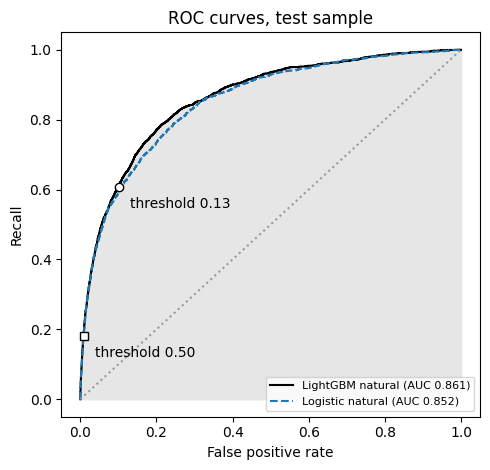

AUC 0.8610 | Gini 0.7220
With the odds multiplied by 5: mean PD 18.8% (before 6.6%) | AUC 0.8610


In [18]:
fig, ax = plt.subplots(figsize=(5, 4.8))
for name, style in [('LightGBM natural', 'k-'), ('Logistic natural', '--')]:
    fpr, tpr, _ = roc_curve(y_te, P_te[name])
    ax.plot(fpr, tpr, style, lw=1.5, label=f"{name} (AUC {roc_auc_score(y_te, P_te[name]):.3f})")
fpr, tpr, _ = roc_curve(y_te, P_te['LightGBM natural'])
ax.fill_between(fpr, tpr, 0, color='0.9', zorder=0)
ax.plot([0, 1], [0, 1], ':', color='0.6')
for u, mk in [(U_013, 'o'), (0.5, 's')]:
    c = confusion(y_te, P_te['LightGBM natural'], u)
    ax.plot(c['FP rate'], c['recall'], mk, color='k', mfc='white'); ax.annotate(f'threshold {u:.2f}', (c['FP rate'] + .03, c['recall'] - .06))
ax.set(xlabel='False positive rate', ylabel='Recall', title='ROC curves, test sample'); ax.legend(fontsize=8, loc='lower right')
plt.tight_layout(); plt.show()
p = P_te['LightGBM natural']
q5 = expit(logit(p) + np.log(5))   # multiplies the odds by 5: a strictly increasing transformation
print(f"AUC {roc_auc_score(y_te, p):.4f} | Gini {2 * roc_auc_score(y_te, p) - 1:.4f}")
print(f"With the odds multiplied by 5: mean PD {q5.mean():.1%} (before {p.mean():.1%}) | AUC {roc_auc_score(y_te, q5):.4f}")

**Conclusion.** LightGBM trained on the natural data has an AUC of 0.861 (Gini 0.722) and the logistic model 0.852 (Gini 0.704); their curves almost overlap. Multiplying the odds by five takes the mean PD from 6.6% to 18.8% and leaves the AUC exactly unchanged. **The Gini does not see the level of the probability**: a model can rank very well with completely wrong PDs. That is why calibration is measured separately.

### 5.3 Calibration

A PD model is **calibrated** if, among the borrowers who receive a PD of $q$, the share who default is $q$. It is checked in three ways:

- **Decile plot**: the mean PD of each decile of predicted PD against its observed rate; a calibrated model lies on the diagonal. `calibration_groups` groups by quantiles and adds a 95% Jeffreys interval for each rate.
- **Calibration intercept** $a$: solves $\operatorname{logit}\Pr(Y=1)=a+\operatorname{logit}\hat p$ with the slope fixed at one. If $a=0$ the average level is right; if $a<0$ the model overestimates.
- **Calibration slope** $b$: from $\operatorname{logit}\Pr(Y=1)=a+b\operatorname{logit}\hat p$. If $b<1$ the PDs are too extreme; if $b>1$ they are too compressed.

`metrics(y, p)` computes all of this together with the Gini, the log-loss and the Brier score.

**Function `safe_p(p)`**: checks that the probabilities are finite and in $[0,1]$, and clips them to $[10^{-10}, 1-10^{-10}]$ so that the logit and the log-loss are always defined.

**Function `calibration_intercept_slope(y, p)`**

- *Purpose:* the two numbers that summarise global calibration.
- *Logic:* the intercept $a$ solves $\sum_i \text{expit}(a+\operatorname{logit}p_i)=\sum_i y_i$ (the score equation of a logistic regression whose only free parameter is the intercept, with $\operatorname{logit}p$ as a fixed offset), found with the root finder `brentq`. The slope $b$ comes from a binomial GLM of $y$ on $\operatorname{logit}p$ with a free intercept, fitted with `statsmodels`.
- *Output:* $(a, b)$.

**Function `metrics(y, p, prev_ref)`**: returns ROC-AUC, Gini, average precision, log-loss, Brier score, Brier skill score (improvement over predicting the training default rate `PREV` for everyone), mean PD, observed rate and calibration intercept and slope.

**Function `metrics_table(P, y)`**: applies `metrics` to a dictionary of models and returns one row per model.

**Function `calibration_groups(y, p, n_bins)`**: groups borrowers by deciles of predicted PD and returns, for each group, its size, defaults, mean PD, observed rate and a 95% Jeffreys interval for the observed rate (the quantiles of a Beta$(D+\tfrac12,\,N-D+\tfrac12)$ distribution).

In [19]:
def safe_p(p):
    p = np.asarray(p, dtype=float)
    if not np.isfinite(p).all() or np.any((p < 0) | (p > 1)):
        raise ValueError('Probabilities outside [0, 1] or not finite.')
    return np.clip(p, 1e-10, 1 - 1e-10)

def calibration_intercept_slope(y, p):
    y, lp = np.asarray(y), logit(safe_p(p))
    a = brentq(lambda a: expit(a + lp).sum() - y.sum(), -80, 80)
    m = sm.GLM(y, sm.add_constant(lp, has_constant='add'), family=sm.families.Binomial()).fit(maxiter=100)
    return a, float(m.params[1])

def metrics(y, p, prev_ref=None):
    y, p = np.asarray(y), safe_p(p)
    a, b = calibration_intercept_slope(y, p)
    auc, brier = roc_auc_score(y, p), brier_score_loss(y, p)
    brier_null = brier_score_loss(y, np.full(len(y), PREV if prev_ref is None else prev_ref))
    return {'ROC-AUC': auc, 'Gini': 2 * auc - 1, 'AP': average_precision_score(y, p),
            'LogLoss': log_loss(y, p, labels=[0, 1]), 'Brier': brier, 'Brier skill': 1 - brier / brier_null,
            'Mean PD': p.mean(), 'Observed rate': y.mean(), 'Cal. intercept': a, 'Cal. slope': b}

def metrics_table(P, y):
    return pd.DataFrame({k: metrics(y, p) for k, p in P.items()}).T

def calibration_groups(y, p, n_bins=10):
    data = pd.DataFrame({'y': y, 'p': p})
    data['group'] = pd.qcut(data.p, q=n_bins, duplicates='drop')
    t = data.groupby('group', observed=True).agg(N=('y', 'size'), D=('y', 'sum'), pred=('p', 'mean'), obs=('y', 'mean'))
    t['lo'] = beta_dist.ppf(.025, t.D + .5, t.N - t.D + .5)
    t['hi'] = beta_dist.ppf(.975, t.D + .5, t.N - t.D + .5)
    return t

### 5.4 Proper scoring rules

The **log-loss** of an observation is $-[y\ln q+(1-y)\ln(1-q)]$ and the **Brier score** is $(y-q)^2$. Unlike the Gini, they penalise a wrong level. And they have a key property: if the true PD is $p$ and the model reports $q$, the expected log-loss $-p\ln q-(1-p)\ln(1-q)$ is minimised at $q=p$ for every $p$ (its derivative $-p/q+(1-p)/(1-q)$ is zero only at $q=p$). A rule with this property is called **strictly proper**. A model fitted by maximum likelihood, such as logistic regression or boosting with a log-loss objective, aims at the true PD; a rare event does not change that target, it only makes it harder to estimate precisely. Aiming is not the same as reaching: whether a fitted model gets there is checked by measuring its calibration.

The cell computes what it costs to report a wrong PD for a borrower whose true PD is 5%, and plots the expected log-loss as a function of the reported PD.

Reported PD 5%: expected log-loss 0.199 | expected Brier score 0.048
Reported PD 25%: expected log-loss 0.343 | expected Brier score 0.087
Reported PD 50%: expected log-loss 0.693 | expected Brier score 0.250


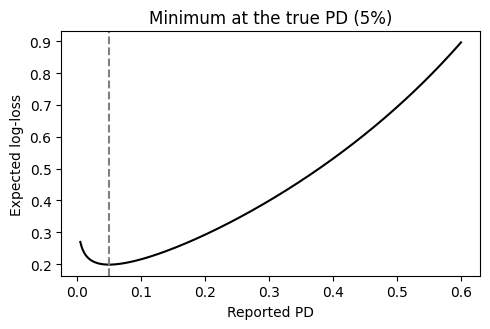

In [20]:
p_true = 0.05
for q in (0.05, 0.25, 0.50):
    ll = -(p_true * np.log(q) + (1 - p_true) * np.log(1 - q))
    br = p_true * (1 - q) ** 2 + (1 - p_true) * q ** 2
    print(f'Reported PD {q:.0%}: expected log-loss {ll:.3f} | expected Brier score {br:.3f}')
qs = np.linspace(.005, .6, 300)
plt.figure(figsize=(5, 3.4))
plt.plot(qs, -(p_true * np.log(qs) + (1 - p_true) * np.log(1 - qs)), 'k')
plt.axvline(p_true, color='0.5', ls='--'); plt.xlabel('Reported PD'); plt.ylabel('Expected log-loss')
plt.title('Minimum at the true PD (5%)'); plt.tight_layout(); plt.show()

**Conclusion of section 5.** Reporting 5% when the true PD is 5% gives an expected log-loss of 0.199; reporting 25%, 0.343; reporting 50%, where a perfectly balanced sample pushes a model with no information, 0.693. Three things have to be measured, and none replaces another: the ranking (Gini), the level and spread of the PDs (intercept, slope, decile plot) and the overall quality of the probability (log-loss, Brier score).

## 6. What rebalancing does to the PD

### 6.1 The prior shift

By Bayes' rule, the odds of default of a borrower are

$$\frac{p(x)}{1-p(x)}=\frac{\pi}{1-\pi}\cdot\frac{f_1(x)}{f_0(x)},$$

the product of how common default is ($\pi$, the default rate of the population) and how much more typical $x$ is of a defaulter than of a good borrower (the likelihood ratio $f_1/f_0$).

**Undersampling** keeps $f_0$ and $f_1$ but changes $\pi$: if a fraction $r$ of the non-defaults is kept, the odds in the sample are the population odds divided by $r$, and the logit of every PD rises by $-\ln r$. **Class weights** have the same effect in expectation, with factor $w_1/w_0$. **SMOTE** is different: the synthetic points are borrowers that do not exist, placed on segments between real defaulters, so it also changes $f_1$ and there is no closed-form correction.

The cell compares the theoretical shift $-\ln r$ with the observed difference between the logits of the undersampled and the natural logistic models, borrower by borrower, on the test sample.

In [21]:
diff = logit(np.clip(P_te['Logistic undersampling'], 1e-10, 1 - 1e-10)) - logit(np.clip(P_te['Logistic natural'], 1e-10, 1 - 1e-10))
print(f'Theoretical -ln r: {-np.log(r):.3f}')
print(f'Observed difference of logits: mean {diff.mean():.3f} | standard deviation {diff.std():.3f}')
for pd_nat in (0.02, 0.067):
    o = pd_nat / (1 - pd_nat) / r
    print(f'A PD of {pd_nat:.1%} becomes {o / (1 + o):.1%}')

Theoretical -ln r: 2.636
Observed difference of logits: mean 2.548 | standard deviation 0.211
A PD of 2.0% becomes 22.2%
A PD of 6.7% becomes 50.1%


**Conclusion.** The theoretical shift is 2.64 and the observed difference between logits averages 2.55, with a small dispersion (0.21): undersampling moves almost every PD by the same constant on the logit scale. A PD of 2% becomes about 22%, and one of 6.7% about 50%. The dispersion is not zero because the model is regularised and was fitted on far fewer observations, so its slopes also move a little.

### 6.2 Recalibration

A PD with a distorted level can be repaired after training:

- **Prior correction** (`prior_correction`): divides the odds by the factor of section 6.1, $q=f\hat p/(f\hat p+1-\hat p)$, with $f=r$ for undersampling and $f=w_0/w_1$ for weights. It needs no data, and it is exact only for a model that reaches its population target.
- **Logistic recalibration** (`fit_calibrator(..., 'logistic')`): fits $\operatorname{logit}q=a+b\operatorname{logit}\hat p$ on the calibration sample, which has the natural default rate.
- **Isotonic regression** (`fit_calibrator(..., 'isotonic')`): fits the best non-decreasing step function.

The first two are strictly increasing transformations and preserve the order of borrowers, and therefore the Gini. Isotonic regression is only non-decreasing: it maps whole ranges of scores to the same value, and those ties can lower the Gini. The cell checks it on LightGBM with SMOTE.

**Function `prior_correction(p, factor)`**: adds $\ln(\text{factor})$ to the logit of every PD, that is, multiplies its odds by `factor`. With `factor` equal to $r$ (undersampling) or $n_{\text{pos}}/n_{\text{neg}}$ (balanced weights) it undoes the shift of section 6.1.

**Function `fit_calibrator(p, y, method)`**

- *Purpose:* fit a recalibration on one sample and return it as a function that can be applied to any other.
- *Inputs:* the PDs and outcomes of the calibration sample, and the method.
- *Logic, `'logistic'`:* fits $\operatorname{logit}q=a+b\operatorname{logit}p$ by minimising the average log-loss with `scipy.optimize.minimize` (method L-BFGS-B), using its analytic gradient. The slope is constrained to $b\ge0$ so that the recalibration can never reverse the order of borrowers.
- *Logic, `'isotonic'`:* fits scikit-learn's `IsotonicRegression`, the best non-decreasing step function from $p$ to the observed rate; values outside the calibration range are clipped to its ends.
- *Output:* a function that maps new PDs to recalibrated PDs.

In [22]:
def prior_correction(p, factor):
    return expit(logit(safe_p(p)) + np.log(factor))

def fit_calibrator(p, y, method='logistic'):
    p, y = safe_p(p), np.asarray(y, dtype=float)
    if method == 'isotonic':
        m = IsotonicRegression(y_min=0, y_max=1, out_of_bounds='clip').fit(p, y)
        return lambda q: safe_p(m.predict(safe_p(q)))
    A = np.column_stack([np.ones(len(p)), logit(p)])
    def objective(b):
        z = A @ b
        return np.mean(np.logaddexp(0, z) - y * z), A.T @ (expit(z) - y) / len(y)
    opt = minimize(objective, np.array([0., 1.]), jac=True, bounds=[(None, None), (0, None)],
                   method='L-BFGS-B', options={'maxiter': 1000, 'ftol': 1e-12, 'gtol': 1e-8})
    if not opt.success:
        raise RuntimeError('Calibrator did not converge: ' + str(opt.message))
    return lambda q: expit(np.column_stack([np.ones(len(q)), logit(safe_p(q))]) @ opt.x)

In [23]:
p_sm = P_te['LightGBM SMOTE']
for method in ('logistic', 'isotonic'):
    q = fit_calibrator(P_ca['LightGBM SMOTE'], y_ca, method)(p_sm)
    print(f'{method:9s}: Gini {2 * roc_auc_score(y_te, q) - 1:.4f} (raw {2 * roc_auc_score(y_te, p_sm) - 1:.4f}) | distinct values: {len(np.unique(q)):,}')

logistic : Gini 0.7074 (raw 0.7074) | distinct values: 29,591
isotonic : Gini 0.7058 (raw 0.7074) | distinct values: 100


**Conclusion.** Logistic recalibration leaves the Gini exactly unchanged; isotonic regression produces a limited number of distinct values and its Gini moves because of the ties. With the full calibration sample the effect is small; with few defaults it can be large. None of the three methods can restore an order that rebalancing has damaged.

## 7. Evidence

### 7.1 Raw results

The table reports, on the test sample, the Gini, the log-loss, the mean PD and the calibration intercept and slope of the eight models, without any correction. It corresponds to Table 5 of the note (Table 1 of the introduction is an excerpt).

,Gini,LogLoss,Brier,Mean PD,Observed rate,Cal. intercept,Cal. slope
Logistic natural,0.7044,0.1836,0.0501,0.0662,0.0668,0.0141,0.9971
Logistic weights,0.7083,0.4688,0.1436,0.3340,0.0668,-2.6951,0.8641
Logistic undersampling,0.7079,0.4704,0.1437,0.3338,0.0668,-2.7102,0.8418
Logistic SMOTE,0.7063,0.4661,0.1436,0.3310,0.0668,-2.6867,0.8627
LightGBM natural,0.7220,0.1792,0.0493,0.0659,0.0668,0.0192,0.9807
LightGBM scale_pos_weight,0.7220,0.4265,0.1369,0.3021,0.0668,-2.5236,0.9729
LightGBM undersampling,0.7186,0.4568,0.1459,0.3208,0.0668,-2.6506,0.9489
LightGBM SMOTE,0.7074,0.2314,0.0650,0.1544,0.0668,-1.2291,0.9862


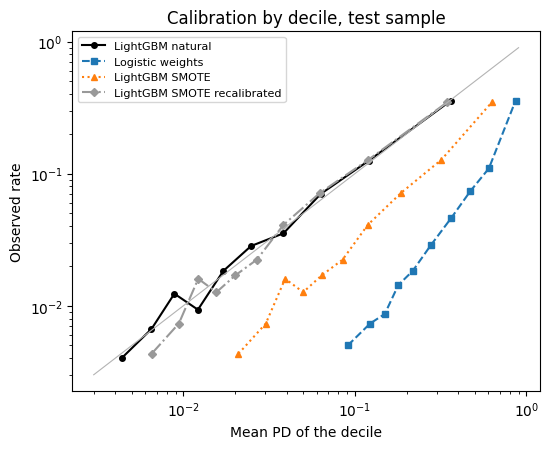

In [24]:
T_raw = metrics_table(P_te, y_te)
display(T_raw[['Gini', 'LogLoss', 'Brier', 'Mean PD', 'Observed rate', 'Cal. intercept', 'Cal. slope']].round(4))

fig, ax = plt.subplots(figsize=(5.6, 4.6))
for name, st in [('LightGBM natural', 'ko-'), ('Logistic weights', 's--'), ('LightGBM SMOTE', '^:')]:
    t = calibration_groups(y_te, P_te[name]); ax.plot(t.pred, t.obs, st, ms=4, label=name)
q_rec = fit_calibrator(P_ca['LightGBM SMOTE'], y_ca, 'logistic')(P_te['LightGBM SMOTE'])
t = calibration_groups(y_te, q_rec); ax.plot(t.pred, t.obs, 'D-.', ms=4, color='0.6', label='LightGBM SMOTE recalibrated')
ax.plot([3e-3, .9], [3e-3, .9], color='0.7', lw=.8); ax.set_xscale('log'); ax.set_yscale('log')
ax.set(xlabel='Mean PD of the decile', ylabel='Observed rate', title='Calibration by decile, test sample'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Conclusion.** The models trained on the natural data show a well calibrated aggregate level without any correction: mean PD of 6.6% against an observed 6.7%, intercepts close to zero and slopes close to one. Every rebalanced model overstates the PD by a factor between two and five; for undersampling and weights the intercepts (around −2.7) match the theoretical shift. The ranking barely moves: the rebalanced logistic models gain about 0.004 of Gini, and LightGBM with SMOTE loses about 0.015. In the decile plot the rebalanced models lie to the right of the diagonal: for the same observed rate they predict several times more.

### 7.2 After recalibration

The table compares, for each model, the raw version, the prior correction (when a factor exists) and a logistic recalibration fitted on the calibration sample. It corresponds to Table 6 of the note.

In [25]:
P_prior = {k: prior_correction(P_te[k], f) for k, f in FACTOR.items()}
P_recal = {k: fit_calibrator(P_ca[k], y_ca, 'logistic')(p) for k, p in P_te.items()}
rows = []
for k in P_te:
    for version, p in [('raw', P_te[k]), ('prior correction', P_prior.get(k)), ('logistic recalibration', P_recal[k])]:
        if p is not None:
            m = metrics(y_te, p)
            rows.append((k, version, m['Gini'], m['LogLoss'], m['Brier'], m['Mean PD'], m['Cal. slope']))
display(pd.DataFrame(rows, columns=['model', 'version', 'Gini', 'LogLoss', 'Brier', 'Mean PD', 'Cal. slope']).set_index(['model', 'version']).round(4))

Gini  LogLoss  Brier  Mean PD  Cal. slope
model                     version                                                           
Logistic natural          raw                    0.7044   0.1836 0.0501   0.0662      0.9971
                          logistic recalibration 0.7044   0.1836 0.0501   0.0660      1.0175
Logistic weights          raw                    0.7083   0.4688 0.1436   0.3340      0.8641
                          prior correction       0.7083   0.1848 0.0507   0.0695      0.8641
                          logistic recalibration 0.7083   0.1836 0.0501   0.0660      1.0204
Logistic undersampling    raw                    0.7079   0.4704 0.1437   0.3338      0.8418
                          prior correction       0.7079   0.1860 0.0510   0.0701      0.8418
                          logistic recalibration 0.7079   0.1842 0.0503   0.0660      1.0136
Logistic SMOTE            raw                    0.7063   0.4661 0.1436   0.3310      0.8627
                          logistic recalibration 0.7063   0.1837 0.0502   0.0659      1.0193
LightGBM natural          raw                    0.7220   0.1792 0.0493   0.0659      0.9807
                          logistic recalibration 0.7220   0.1792 0.0493   0.0659      1.0016
LightGBM scale_pos_weight raw                    0.7220   0.4265 0.1369   0.3021      0.9729
                          prior correction       0.7220   0.1795 0.0493   0.0615      0.9729
                          logistic recalibration 0.7220   0.1792 0.0493   0.0656      1.0116
LightGBM undersampling    raw                    0.7186   0.4568 0.1459   0.3208      0.9489
                          prior correction       0.7186   0.1804 0.0497   0.0675      0.9489
                          logistic recalibration 0.7186   0.1803 0.0496   0.0655      1.0194
LightGBM SMOTE            raw                    0.7074   0.2314 0.0650   0.1544      0.9862
                          logistic recalibration 0.7074   0.1834 0.0505   0.0658      1.0086

**Conclusion.** The prior correction brings the weighted logistic model close but leaves it slightly high (6.9%), and for LightGBM with `scale_pos_weight` it overshoots to 6.1%. Weighting does shift the population target as section 6.1 states, but the correction is exact only for a model that reaches that target, and a fitted model with limited capacity, regularisation and a finite sample does not reach it exactly. Logistic recalibration on a separate sample fixes the level in every case. What it cannot fix is the ranking: LightGBM with SMOTE stays at a Gini of 0.707, and its log-loss stays above that of the model trained on the natural data.

### 7.3 Stability across five data splits

A single split can flatter or punish any model. To check that the conclusions do not depend on it, `run_partition(seed)` repeats **the whole chain** with another seed: split, preprocessing, training, recalibration and evaluation. For each model it reports the Gini, the mean PD and the log-loss after recalibration. The models are then compared with LightGBM trained on the natural data **seed by seed**: the paired difference removes the variation that is common to all models (a "hard" partition affects all of them) and leaves only what can be attributed to the model.

In [26]:
def run_partition(s):
    a, b, c, d = split(df, s)
    ps = fit_preprocessing(a)
    Xa, Xc, Xd = [apply_preprocessing(z, ps) for z in (a, c, d)]
    ya, yc, yd = a.y.to_numpy(), c.y.to_numpy(), d.y.to_numpy()
    sc = StandardScaler().fit(log_features(Xa))
    La, Lc, Ld = [sc.transform(log_features(X)) for X in (Xa, Xc, Xd)]
    w, _ = balanced_weights(ya); spw = float((ya == 0).sum() / ya.sum())
    scs = StandardScaler().fit(Xa)
    Xs, ys = SMOTE(random_state=s).fit_resample(scs.transform(Xa), ya)
    Xs = pd.DataFrame(scs.inverse_transform(Xs), columns=Xa.columns)
    models = {'Logistic natural': (fit_logit(La, ya), Lc, Ld), 'Logistic weights': (fit_logit(La, ya, w), Lc, Ld),
              'LightGBM natural': (fit_lgb(Xa, ya, random_state=s), Xc, Xd),
              'LightGBM scale_pos_weight': (fit_lgb(Xa, ya, scale_pos_weight=spw, random_state=s), Xc, Xd),
              'LightGBM SMOTE': (fit_lgb(Xs, ys, random_state=s), Xc, Xd)}
    out = []
    for k, (m, A, B) in models.items():
        pc, pt = predict_pd(m, A), predict_pd(m, B)
        mt = metrics(yd, pt)
        out.append({'seed': s, 'model': k, 'Gini': mt['Gini'], 'Mean PD': mt['Mean PD'],
                    'LogLoss recal': log_loss(yd, fit_calibrator(pc, yc, 'logistic')(pt))})
    return out

t0 = time.perf_counter()
SEEDS = [SEED + 1000 * i for i in range(5)]
rob = pd.DataFrame([row for s in SEEDS for row in run_partition(s)])
ref = rob[rob.model == 'LightGBM natural'].set_index('seed').Gini
rob['ΔGini'] = rob.Gini - rob.seed.map(ref)
order = ['LightGBM natural', 'LightGBM scale_pos_weight', 'LightGBM SMOTE', 'Logistic natural', 'Logistic weights']
display(rob.groupby('model').agg(Gini=('Gini', 'mean'), SD_Gini=('Gini', 'std'), ΔGini=('ΔGini', 'mean'),
        ΔGini_min=('ΔGini', 'min'), ΔGini_max=('ΔGini', 'max'), partitions_better=('ΔGini', lambda v: int((v > 0).sum())),
        Mean_PD=('Mean PD', 'mean'), LogLoss_recal=('LogLoss recal', 'mean')).loc[order].round(4))
print(f'{time.perf_counter() - t0:.0f} s')

,Gini,SD_Gini,ΔGini,ΔGini_min,ΔGini_max,partitions_better,Mean_PD,LogLoss_recal
model,,,,,,,,
LightGBM natural,0.7255,0.0052,0.0000,0.0000,0.0000,0,0.0668,0.1787
LightGBM scale_pos_weight,0.7252,0.0048,-0.0003,-0.0012,0.0017,1,0.3049,0.1789
LightGBM SMOTE,0.7082,0.0043,-0.0173,-0.0216,-0.0136,0,0.1547,0.1830
Logistic natural,0.7047,0.0077,-0.0208,-0.0271,-0.0176,0,0.0670,0.1838
Logistic weights,0.7079,0.0072,-0.0176,-0.0229,-0.0137,0,0.3367,0.1839


34 s


**Conclusion.** Weighting the defaults in LightGBM does not change its ranking in any meaningful way: the mean difference in Gini is −0.0003 and it wins in one partition out of five. SMOTE loses in all five (−0.017 on average, between −0.022 and −0.014). After recalibration SMOTE still has a higher log-loss (0.1830 against 0.1787). The standard deviation of the Gini across partitions is about 0.005, the same order as the small differences between variants; that is why the comparison has to be paired before a difference is read as an improvement. The five partitions measure stability within this dataset and these settings; they do not show that the result holds for every portfolio.

### 7.4 SMOTE and binary indicators: a check with SMOTENC

SMOTE creates a synthetic default on the segment between two real ones. For continuous variables that is a plausible borrower; for binary indicators it is not: halfway between a defaulter with missing income and one without, SMOTE produces `f_no_income = 0.5`, a value no real borrower can have. Because the variables are standardised and transformed back, a value such as 0.9999999999999999 is rounding error and should not count as a fraction; the count below uses a tolerance and measures the distance to the nearest of 0 and 1. **SMOTENC** (SMOTE for nominal and continuous features, available in `imbalanced-learn`) treats the listed columns as categorical: it still interpolates the continuous variables, but gives each categorical column the most frequent value among the neighbours.

The cell counts how many synthetic borrowers of the SMOTE sample of section 3 have fractional indicators, refits LightGBM with SMOTENC on the same split (standardised variables, the four indicators declared categorical), and then repeats the comparison of section 7.3 on the five splits.

**Function `smotenc_sample(X, y, seed)`**: standardises `X`, applies SMOTENC with the indicator columns declared categorical, and transforms back to the original scale; because the categorical columns only take their two standardised values, they return exactly to 0 and 1.

In [27]:
from imblearn.over_sampling import SMOTENC
FLAGS = [i for i, c in enumerate(X_tr.columns) if c.startswith('f_')]

def smotenc_sample(X, y, seed):
    scl = StandardScaler().fit(X)
    Xs, ys = SMOTENC(categorical_features=FLAGS, random_state=seed).fit_resample(scl.transform(X), y)
    return pd.DataFrame(scl.inverse_transform(Xs), columns=X.columns).round({X.columns[i]: 0 for i in FLAGS}), ys

synthetic = X_sm.iloc[len(X_tr):]
v = synthetic.iloc[:, FLAGS].to_numpy()
fractional = np.minimum(np.abs(v), np.abs(v - 1)) > 1e-9   # distance to the nearest of 0 and 1, beyond rounding error
frac = fractional.any(axis=1).mean()
print(f'SMOTE: {int(fractional.any(axis=1).sum()):,} of {len(synthetic):,} synthetic defaults ({frac:.2%}) have at least one fractional indicator')
print('By indicator:', {X_tr.columns[i]: int(n) for i, n in zip(FLAGS, fractional.sum(axis=0))})

X_nc, y_nc = smotenc_sample(X_tr, y_tr, SEED)
m_nc = fit_lgb(X_nc, y_nc)
p_ca_nc, p_te_nc = predict_pd(m_nc, X_ca), predict_pd(m_nc, X_te)
rows = []
for name, pc, pt in [('LightGBM natural', P_ca['LightGBM natural'], P_te['LightGBM natural']),
                     ('LightGBM SMOTE', P_ca['LightGBM SMOTE'], P_te['LightGBM SMOTE']),
                     ('LightGBM SMOTENC', p_ca_nc, p_te_nc)]:
    raw, rec = metrics(y_te, pt), metrics(y_te, fit_calibrator(pc, y_ca, 'logistic')(pt))
    rows.append((name, raw['Gini'], raw['Mean PD'], raw['LogLoss'], rec['LogLoss']))
display(pd.DataFrame(rows, columns=['model', 'Gini', 'Mean PD raw', 'LogLoss raw', 'LogLoss recalibrated']).set_index('model').round(4))

rows = []
for s in SEEDS:
    a, b, c, d = split(df, s); ps = fit_preprocessing(a)
    Xa, Xd = apply_preprocessing(a, ps), apply_preprocessing(d, ps)
    ya, yd = a.y.to_numpy(), d.y.to_numpy()
    scs = StandardScaler().fit(Xa)
    Xs, ys = SMOTE(random_state=s).fit_resample(scs.transform(Xa), ya)
    Xs = pd.DataFrame(scs.inverse_transform(Xs), columns=Xa.columns)
    Xn, yn = smotenc_sample(Xa, ya, s)
    g_nat = 2 * roc_auc_score(yd, predict_pd(fit_lgb(Xa, ya, random_state=s), Xd)) - 1
    for name, (Xt, yt) in {'SMOTE': (Xs, ys), 'SMOTENC': (Xn, yn)}.items():
        g = 2 * roc_auc_score(yd, predict_pd(fit_lgb(Xt, yt, random_state=s), Xd)) - 1
        rows.append((s, name, g - g_nat))
r5 = pd.DataFrame(rows, columns=['seed', 'variant', 'ΔGini vs natural'])
display(r5.groupby('variant')['ΔGini vs natural'].agg(['mean', 'min', 'max', lambda v: int((v > 0).sum())]).rename(columns={'<lambda_0>': 'splits better'}).round(4))

SMOTE: 257 of 71,472 synthetic defaults (0.36%) have at least one fractional indicator
By indicator: {'f_code9x': 0, 'f_no_income': 245, 'f_no_dependents': 12, 'f_invalid_age': 0}


,Gini,Mean PD raw,LogLoss raw,LogLoss recalibrated
model,,,,
LightGBM natural,0.7220,0.0659,0.1792,0.1792
LightGBM SMOTE,0.7074,0.1544,0.2314,0.1834
LightGBM SMOTENC,0.7074,0.1550,0.2318,0.1834


,mean,min,max,splits better
variant,,,,
SMOTE,-0.0173,-0.0216,-0.0136,0
SMOTENC,-0.0180,-0.0216,-0.0140,0


**Conclusion.** SMOTE does create impossible borrowers, but few in this data: 257 of 71,472 synthetic defaults (0.36%) have a fractional indicator, all of them in the indicators of missing income and missing dependents; the indicator of the delinquency codes stays binary. Declaring the indicators categorical with SMOTENC removes them, but changes nothing in the conclusions: on the main split the Gini is 0.707 with both, the raw mean PD is 15.5% against 15.4% with SMOTE, and across the five splits SMOTENC loses Gini against the natural model in all five (−0.018 on average, against −0.017 for SMOTE). The damage comes from rebalancing itself; the treatment of the indicators makes no difference.

## 8. Where the asymmetry belongs: the threshold

### The rule

Let $C_{FN}$ be the cost of approving a borrower who defaults and $C_{FP}$ the cost of rejecting one who would have paid. For a borrower with calibrated PD $p$, approving has expected cost $p\,C_{FN}$ and rejecting $(1-p)\,C_{FP}$. Rejecting is optimal when

$$p>p^*=\frac{C_{FP}}{C_{FP}+C_{FN}}.$$

With symmetric costs $p^*=0.5$: the default threshold of most software and the source of the 95% accuracy, 0% recall example. The rule needs a calibrated PD; with a distorted PD the threshold no longer means anything.

### Why not maximise F1?

When asked for the best threshold, many analysts search for the one that maximises $F_1=2\,\mathrm{TP}/(2\,\mathrm{TP}+\mathrm{FP}+\mathrm{FN})$, the harmonic mean of precision and recall. The procedure is easy to program and has three problems in credit. The first is that $F_1$ ignores the true negatives, the good borrowers who are approved, which is where the lender earns its margin. The second is that it contains no cost, so the threshold does not move when the margin or the loss given default changes. The third comes from a less known result: for a calibrated PD, the threshold that maximises $F_1$ equals half of the maximum $F_1$ the model can attain (Lipton, Elkan and Narayanaswamy, 2014, *Optimal Thresholding of Classifiers to Maximize F1 Measure*, ECML PKDD). It can never exceed 0.5, and it depends on how well the model discriminates: a better model has a higher maximum $F_1$ and therefore a higher cut-off, while the economics of the portfolio have not changed. In the terms of the rule above, maximising $F_1$ is equivalent to assuming $C_{FN}/C_{FP}=2/F_1^{\max}-1$, a cost ratio that nobody chose.

### The experiment

With the illustrative costs $C_{FN}=1$ and $C_{FP}=0.15$ (a bad loan costs as much as the margin of about 6.7 good ones), $p^*=0.13$.

- `expected_cost(y, p, u)`: average cost per applicant when every borrower with a PD above `u` is rejected.
- `best_threshold_on_validation(y, p)`: searches a grid **on the validation sample** for the threshold with the lowest cost. It represents what an analyst who does not trust the theory would do.

LightGBM trained on the natural data, LightGBM with raw SMOTE and the same model recalibrated are compared with the theoretical threshold and with the threshold searched on validation, all evaluated on the test sample. The cell then measures what happens if the business gets the costs wrong.

value   cost  rejected
model                       threshold                                     
Approve everyone            none                      NaN 0.0668    0.0000
LightGBM natural            theoretical p*         0.1304 0.0402    0.1345
                            searched on validation 0.1236 0.0401    0.1412
LightGBM SMOTE raw          theoretical p*         0.1304 0.0512    0.3248
                            searched on validation 0.3332 0.0408    0.1398
LightGBM SMOTE recalibrated theoretical p*         0.1304 0.0411    0.1342
                            searched on validation 0.1315 0.0411    0.1333

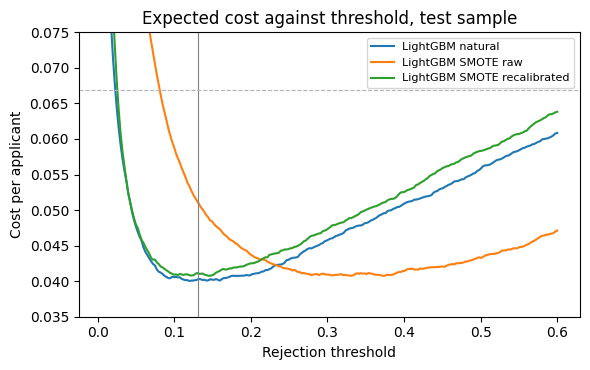

Usual threshold 0.5 on the natural model: cost 0.0559
Sensitivity to errors in the costs (true costs: 1 and 0.15):
  if the business assumes C_FP = 0.05: p* = 0.048, cost 0.0484 (+20% above the optimum)
  if the business assumes C_FP = 0.30: p* = 0.231, cost 0.0422 (+5% above the optimum)


In [28]:
C_FN, C_FP = 1.0, 0.15
P_STAR = C_FP / (C_FP + C_FN)
def expected_cost(y, p, u, c_fn=C_FN, c_fp=C_FP):
    y = np.asarray(y); rej = np.asarray(p) > u
    return np.mean(c_fn * (~rej & (y == 1)) + c_fp * (rej & (y == 0)))
def best_threshold_on_validation(y, p):
    grid = np.r_[0, np.linspace(.005, .95, 240), 1.]
    return float(grid[np.argmin([expected_cost(y, p, u) for u in grid])])

cal_sm = fit_calibrator(P_ca['LightGBM SMOTE'], y_ca, 'logistic')
rules = [('LightGBM natural', P_va['LightGBM natural'], P_te['LightGBM natural']),
         ('LightGBM SMOTE raw', P_va['LightGBM SMOTE'], P_te['LightGBM SMOTE']),
         ('LightGBM SMOTE recalibrated', cal_sm(P_va['LightGBM SMOTE']), cal_sm(P_te['LightGBM SMOTE']))]
rows = [('Approve everyone', 'none', np.nan, C_FN * y_te.mean(), 0.0)]
for name, pv, pt in rules:
    for kind, u in [('theoretical p*', P_STAR), ('searched on validation', best_threshold_on_validation(y_va, pv))]:
        rows.append((name, kind, u, expected_cost(y_te, pt, u), (pt > u).mean()))
display(pd.DataFrame(rows, columns=['model', 'threshold', 'value', 'cost', 'rejected']).set_index(['model', 'threshold']).round(4))

grid = np.linspace(.005, .6, 240)
plt.figure(figsize=(6, 3.8))
for name, _, pt in rules:
    plt.plot(grid, [expected_cost(y_te, pt, u) for u in grid], label=name)
plt.axvline(P_STAR, color='0.5', lw=.8); plt.axhline(C_FN * y_te.mean(), color='0.7', ls='--', lw=.8)
plt.xlabel('Rejection threshold'); plt.ylabel('Cost per applicant'); plt.ylim(.035, .075); plt.legend(fontsize=8)
plt.title('Expected cost against threshold, test sample'); plt.tight_layout(); plt.show()

base = expected_cost(y_te, P_te['LightGBM natural'], P_STAR)
print(f"Usual threshold 0.5 on the natural model: cost {expected_cost(y_te, P_te['LightGBM natural'], 0.5):.4f}")
print('Sensitivity to errors in the costs (true costs: 1 and 0.15):')
for c_fp_assumed in (0.05, 0.30):
    u = c_fp_assumed / (c_fp_assumed + C_FN)
    c = expected_cost(y_te, P_te['LightGBM natural'], u)
    print(f'  if the business assumes C_FP = {c_fp_assumed:.2f}: p* = {u:.3f}, cost {c:.4f} ({c / base - 1:+.0%} above the optimum)')

**Conclusion.** In this experiment the theoretical threshold costs practically the same as the one searched on validation: LightGBM trained on the natural data costs 0.0402 per applicant at $p^*$ and 0.0401 at the threshold searched on validation, against 0.056 at the usual 0.5. The raw SMOTE model, read at the same threshold, rejects a third of the applicants and costs 27% more (0.0512). Its own optimum sits near 0.33, and searching for it on validation brings the cost back to 0.041: the **decision** can be rescued, but with a threshold that theory no longer provides and that has to be searched again whenever the costs change. The **probability** cannot be rescued without recalibration, and pricing, provisions and capital need the probability.

**Where the costs come from.** Only their ratio matters. The cost of approving a defaulter is, in essence, the exposure at default times the loss given default, plus collection and legal costs and the time value of recoveries when the LGD in use does not already include them, minus what was collected before the default. The cost of rejecting a good borrower is the net profit forgone over the horizon (loan rate minus funding cost, on the average balance and the expected life, plus fees) minus servicing costs and the cost of capital. The horizon of the costs must match that of the PD: here, two years.

**How precise must they be?** Less than one might fear, because the cost curve is flat near its minimum: assuming a third of the true forgone profit costs about 20% above the optimum, and assuming twice the true value about 5%. Both errors are smaller than reading a rebalanced model at the theoretical threshold (27%) and much smaller than approving everyone (66%). These figures belong to this dataset and these illustrative costs; in practice the decision should be reported together with a sensitivity analysis.

## 9. Robustness to the treatment of variables

### What is tested

Section 2 showed that utilisation has two groups that the simple preprocessing handles badly (zero and 100+), and that a zero income is a case of its own. This section defines an improved treatment and answers two questions: does it improve the calibration of those groups, and do the conclusions about rebalancing change?

### Functions

- `features_v2(d, par, trees)`: starts from `apply_preprocessing` and adds the indicators `f_util_zero` (utilisation of exactly zero), `f_util_100` (100 or more) and `f_income_zero`. Continuous utilisation is capped at 2 (200%, a plausible overdraft) instead of the 99th percentile. For the 100+ group it is left as missing for the trees (LightGBM learns which side to send missing values to) and imputed with the median for the logistic regression, where the indicator carries the information.
- `log_v2(X)`: applies `log1p` to the skewed variables, for the logistic regression.
- The experiment goes through the same five seeds, compares the simple preprocessing with `features_v2`, accumulates observed (O) and expected (E) defaults by segment, and then repeats the rebalancing comparison with `features_v2`. In the second table, N, O and E are **summed over the five test samples**. The test samples of different seeds overlap, so the same borrower can be counted more than once; the cell also prints how many distinct borrowers and distinct defaults lie behind each accumulated count. For SMOTE on LightGBM, the missing utilisation is temporarily coded as −1, because SMOTE does not accept missing values, and restored afterwards.

In [29]:
def features_v2(d, par, trees):
    X = apply_preprocessing(d, par)
    uu, ii = d.util.to_numpy(), d.income.to_numpy()
    X['f_util_zero'] = (uu == 0).astype(int)
    X['f_util_100'] = (uu >= 100).astype(int)
    X['f_income_zero'] = (ii == 0).astype(int)
    X['util'] = np.where(uu >= 100, np.nan if trees else par['medians']['util'], np.clip(uu, 0, 2))
    return X

def log_v2(X):
    Z = X.copy()
    for c in ['util', 'debt_ratio', 'income', 'open_lines', 'real_estate', 'dependents', 'dpd30', 'dpd60', 'dpd90']:
        Z[c] = np.log1p(Z[c])
    return Z

t0 = time.perf_counter()
rows_v, seg, rows_r, distinct = [], {}, [], {}
for s in SEEDS:
    a, b, c, d = split(df, s); ps = fit_preprocessing(a)
    ya, yd = a.y.to_numpy(), d.y.to_numpy()
    masks = {'util = 0': (d.util == 0).to_numpy(), 'util 100+': (d.util >= 100).to_numpy()}
    variants = {'simple': (log_v2(apply_preprocessing(a, ps)), log_v2(apply_preprocessing(d, ps)), apply_preprocessing(a, ps), apply_preprocessing(d, ps)),
                'improved': (log_v2(features_v2(a, ps, False)), log_v2(features_v2(d, ps, False)), features_v2(a, ps, True), features_v2(d, ps, True))}
    for v, (La0, Ld0, Xa, Xd) in variants.items():
        sc = StandardScaler().fit(La0); La, Ld = sc.transform(La0), sc.transform(Ld0)
        for model, p in [('Logistic', predict_pd(fit_logit(La, ya), Ld)), ('LightGBM', predict_pd(fit_lgb(Xa, ya, random_state=s), Xd))]:
            rows_v.append((s, model, v, 2 * roc_auc_score(yd, p) - 1))
            for name, mk in masks.items():
                o, e, n = seg.get((model, v, name), (0, 0., 0))
                seg[(model, v, name)] = (o + int(yd[mk].sum()), e + float(p[mk].sum()), n + int(mk.sum()))
                ids = distinct.setdefault(name, set()); ids.update(d.index[mk])
        if v == 'improved':
            w, _ = balanced_weights(ya); spw = float((ya == 0).sum() / ya.sum())
            Xf = Xa.fillna(-1); scs = StandardScaler().fit(Xf)
            Xs, ys = SMOTE(random_state=s).fit_resample(scs.transform(Xf), ya)
            Xs = pd.DataFrame(scs.inverse_transform(Xs), columns=Xa.columns); Xs.loc[Xs.util < 0, 'util'] = np.nan
            for k, (m, A) in {'Logistic natural': (fit_logit(La, ya), Ld), 'Logistic weights': (fit_logit(La, ya, w), Ld),
                              'LightGBM natural': (fit_lgb(Xa, ya, random_state=s), Xd),
                              'LightGBM scale_pos_weight': (fit_lgb(Xa, ya, scale_pos_weight=spw, random_state=s), Xd),
                              'LightGBM SMOTE': (fit_lgb(Xs, ys, random_state=s), Xd)}.items():
                p = predict_pd(m, A); rows_r.append((s, k, 2 * roc_auc_score(yd, p) - 1, p.mean()))

g = pd.DataFrame(rows_v, columns=['seed', 'model', 'version', 'Gini'])
g['ΔGini'] = g.Gini - g.set_index(['seed', 'model']).index.map(g[g['version'] == 'simple'].set_index(['seed', 'model']).Gini)
display(g.groupby(['model', 'version']).agg(Gini=('Gini', 'mean'), ΔGini=('ΔGini', 'mean'), improvements=('ΔGini', lambda v: int((v > 0).sum()))).round(4))
display(pd.DataFrame([(m, v, sg, n, o, e, o / e) for (m, v, sg), (o, e, n) in seg.items()],
                     columns=['model', 'version', 'segment', 'N', 'O', 'E', 'O/E']).set_index(['segment', 'model', 'version']).sort_index().round(3))
for name, ids in distinct.items():
    ids = list(ids)
    print(f'{name}: {len(ids):,} distinct borrowers and {int(df.y.loc[ids].sum())} distinct defaults behind the accumulated counts')
rr = pd.DataFrame(rows_r, columns=['seed', 'model', 'Gini', 'Mean PD'])
rr['ΔGini'] = rr.Gini - rr.seed.map(rr[rr.model == 'LightGBM natural'].set_index('seed').Gini)
display(rr.groupby('model').agg(Gini=('Gini', 'mean'), Mean_PD=('Mean PD', 'mean'), ΔGini=('ΔGini', 'mean'),
        partitions_better=('ΔGini', lambda v: int((v > 0).sum()))).round(4))
print(f'{time.perf_counter() - t0:.0f} s')

Gini  ΔGini  improvements
model    version                             
LightGBM improved 0.7260 0.0005             3
         simple   0.7255 0.0000             0
Logistic improved 0.7068 0.0021             5
         simple   0.7047 0.0000             0

N    O        E    O/E
segment   model    version                             
util 100+ LightGBM improved    223   15   9.7100 1.5450
                   simple      223   15  29.4210 0.5100
          Logistic improved    223   15  10.5540 1.4210
                   simple      223   15  26.7390 0.5610
util = 0  LightGBM improved  10662  316 296.5730 1.0660
                   simple    10662  316 293.3220 1.0770
          Logistic improved  10662  316 310.9320 1.0160
                   simple    10662  316 209.6900 1.5070

util = 0: 7,242 distinct borrowers and 211 distinct defaults behind the accumulated counts
util 100+: 155 distinct borrowers and 10 distinct defaults behind the accumulated counts


,Gini,Mean_PD,ΔGini,partitions_better
model,,,,
LightGBM SMOTE,0.7105,0.1541,-0.0155,0
LightGBM natural,0.7260,0.0668,0.0000,0
LightGBM scale_pos_weight,0.7256,0.3051,-0.0004,1
Logistic natural,0.7068,0.0669,-0.0192,0
Logistic weights,0.7096,0.3358,-0.0164,0


45 s


**Conclusion.** The overall Gini improves only slightly with the improved treatment, because the groups involved are small. The important effect is on calibration: with the simple preprocessing, the logistic model predicts only about two thirds of the defaults of the zero-utilisation group (O/E close to 1.5), and both models predict about twice the observed defaults of the 100+ group (O/E close to 0.5). With the improved treatment the zero-utilisation group becomes calibrated in the logistic model; the 100+ group improves, but its 15 default observations across the five test samples come from only 10 distinct borrowers, so it cannot be calibrated precisely. The third table repeats the rebalancing experiment with the improved treatment: the pattern is the same as in section 7. The conclusions about rebalancing do not depend on the preprocessing.

## 10. Conclusions

1. **Understand the fields before modelling.** The codes 96 and 98 are not counts and mark a segment with a 54.6% default rate; missing income carries information and its mechanism is not identified; utilisation has two groups that break the trend; the debt ratio looks useless raw and is weak but real with the right treatment.
2. **Decide first what is being delivered: a label or a probability.** In credit it is almost always a probability, because pricing, provisions and capital use it directly.
3. **Measure ranking and probability separately.** The Gini (equivalent to the AUC) does not see the level of the PDs; calibration (intercept, slope, decile plot) and proper scoring rules (log-loss, Brier score) do.
4. **Train on the natural default rate with a proper loss.** In this dataset, models trained that way had a well calibrated aggregate level and slope without any correction. A proper loss aims at the true PD but does not guarantee reaching it: that has to be checked, by segment as well.
5. **Rebalancing inflates the PD and does not buy ranking.** The rebalanced models predicted mean PDs between 15% and 33% against a true rate of 6.7%. Across five partitions, weighting did not improve the average Gini of LightGBM and SMOTE lowered it in all of them.
6. **Recalibration repairs the level and leaves the order unchanged.** Prior correction and logistic recalibration preserve the Gini; isotonic regression can lower it through ties.
7. **The cost asymmetry belongs in the threshold:** $p^*=C_{FP}/(C_{FP}+C_{FN})$ on a calibrated PD. In this experiment it cost practically the same as a threshold searched on validation; its optimality requires a PD that is calibrated near the cut-off and costs that are correctly defined. It can be explained to the business, and it tolerated reasonable errors in the costs.
8. **If you rebalance, treat it as an experiment:** compare it with the natural model across several partitions, and recalibrate on a separate sample before using the output as a probability.

**Scope.** All the evidence comes from one public dataset with fixed model settings. The five partitions measure stability within this dataset; in another portfolio the magnitudes may change.